                 LOGIN
                   |
                   ↓
        Email + Password
                   |
                   ↓
             Verify User
                   |
                   ↓
        ┌───────────────────┐
        │ Create Payload    │
        │ user_id = 101     │
        │ role = user       │
        │ exp = ...         │
        └─────────┬─────────┘
                  |
                  ↓
        ┌───────────────────┐
        │ Create Header     │
        │ alg = HS256       │
        │ typ = JWT         │
        └─────────┬─────────┘
                  |
                  ↓
           Base64URL Encode
                  |
                  ↓
       HEADER + "." + PAYLOAD
                  |
                  ↓
          HMAC-SHA256
                  ↑
                  |
             SECRET KEY
                  |
                  ↓
              SIGNATURE
                  |
                  ↓
      ┌─────────────────────────┐
      │ HEADER.PAYLOAD.SIGNATURE│
      └────────────┬────────────┘
                   |
                   ↓
                  JWT
                   |
                   ↓
                Client
                   |
                   |
         API Request + JWT
                   |
                   ↓
                Backend
                   |
                   ↓
          Extract JWT
                   |
                   ↓
        Split Header/Payload/
             Signature
                   |
                   ↓
       Header + Payload + Secret
                   |
                   ↓
          HMAC-SHA256 again
                   |
                   ↓
        Calculate New Signature
                   |
                   ↓
        Compare with Received
             Signature
              /       \
             /         \
          Same        Different
           ↓              ↓
         Valid          Reject
           |
           ↓
     Check expiration
           |
           ↓
     Read user_id/claims
           |
           ↓
       Access API

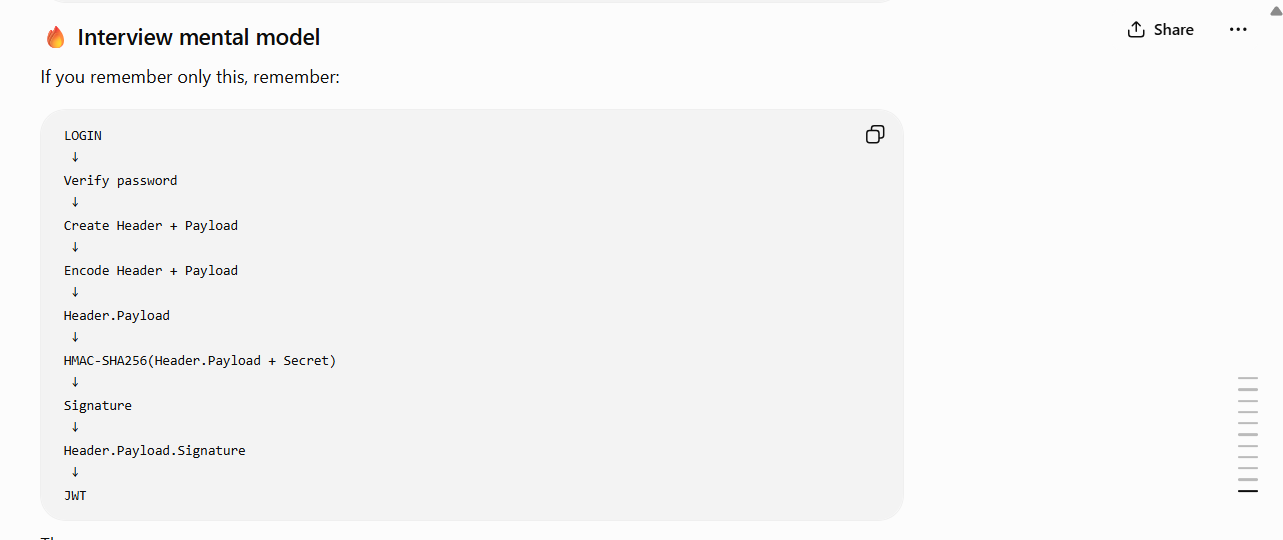

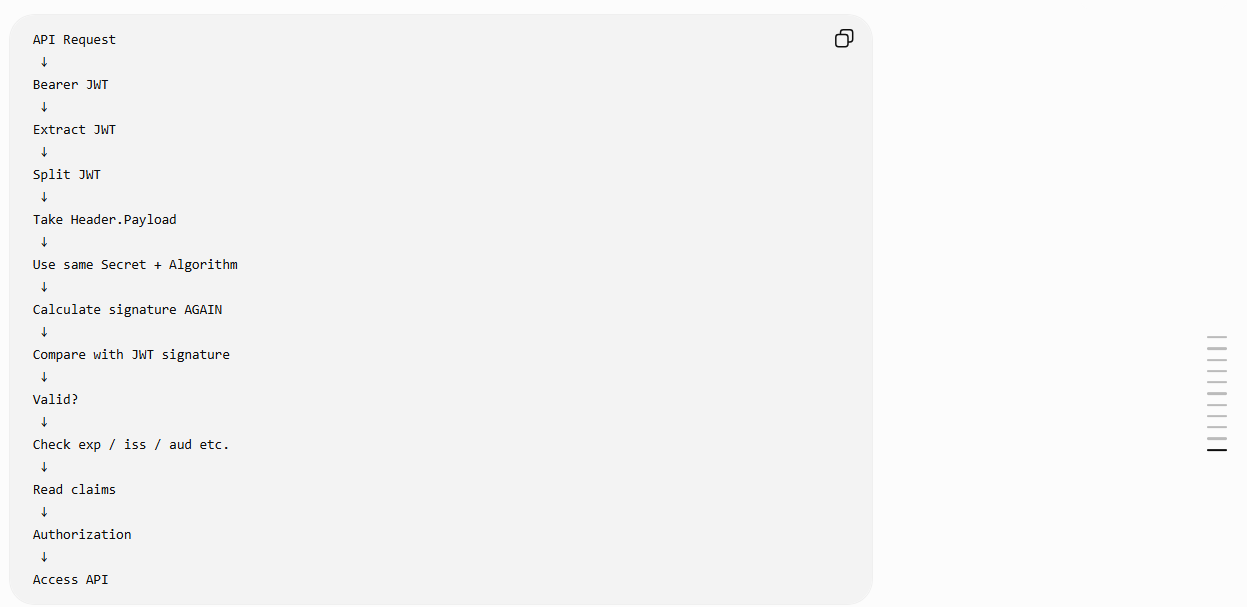

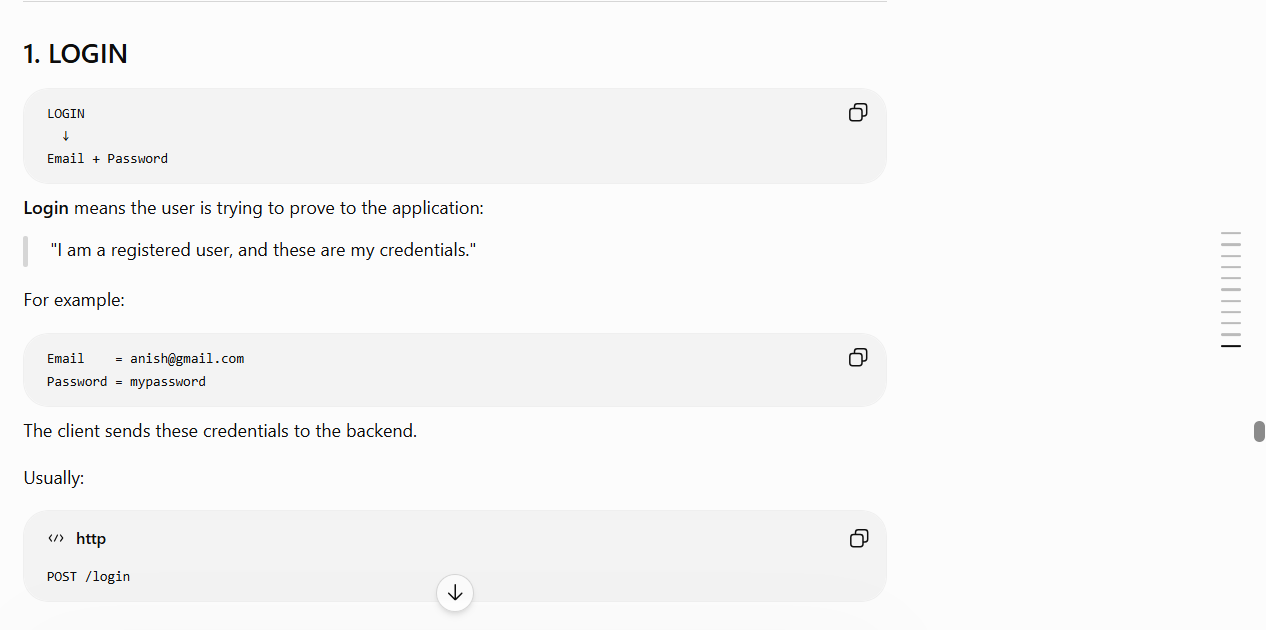

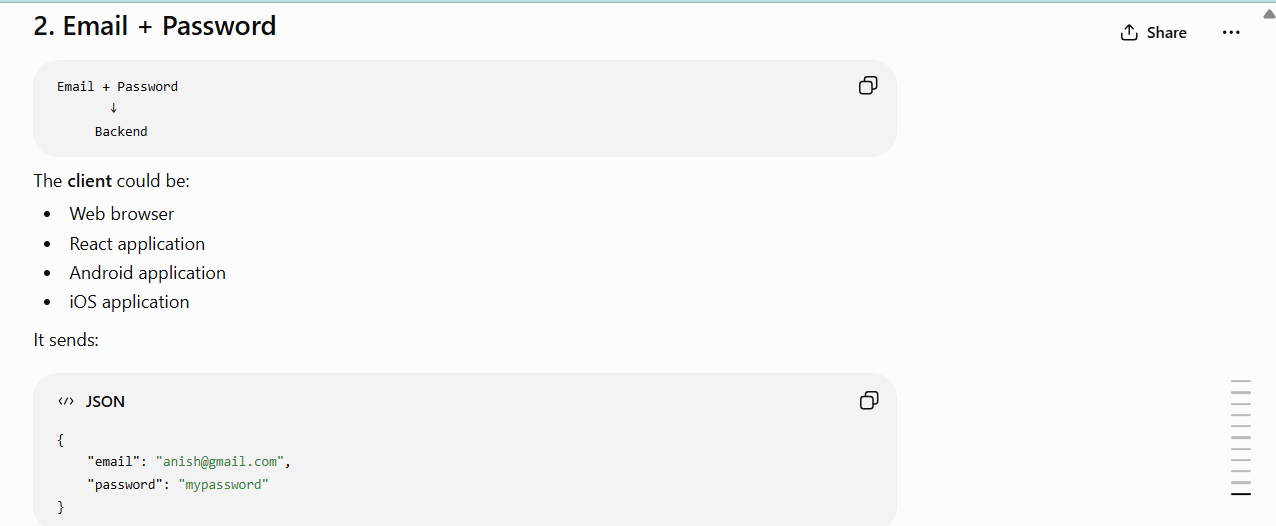

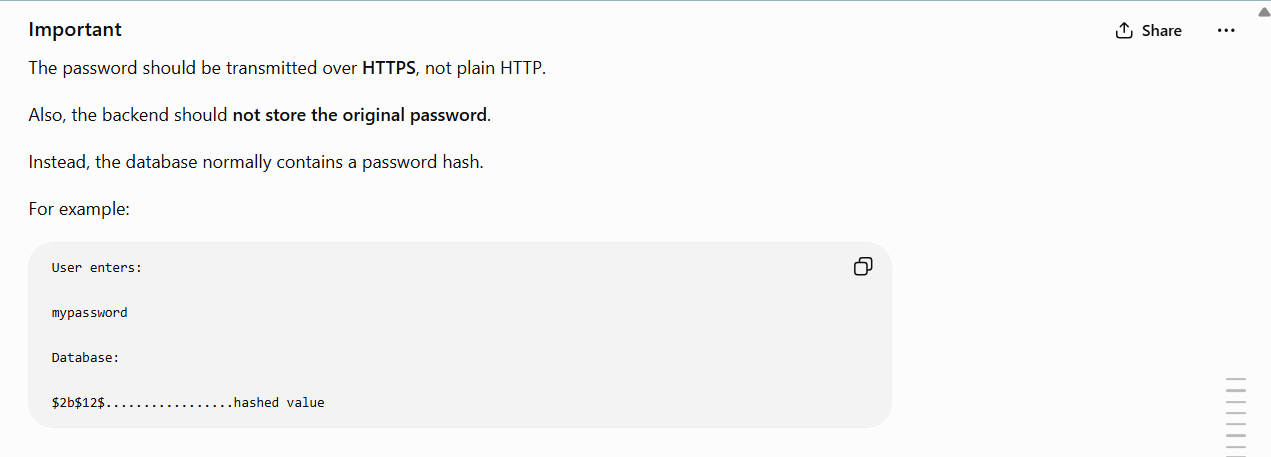

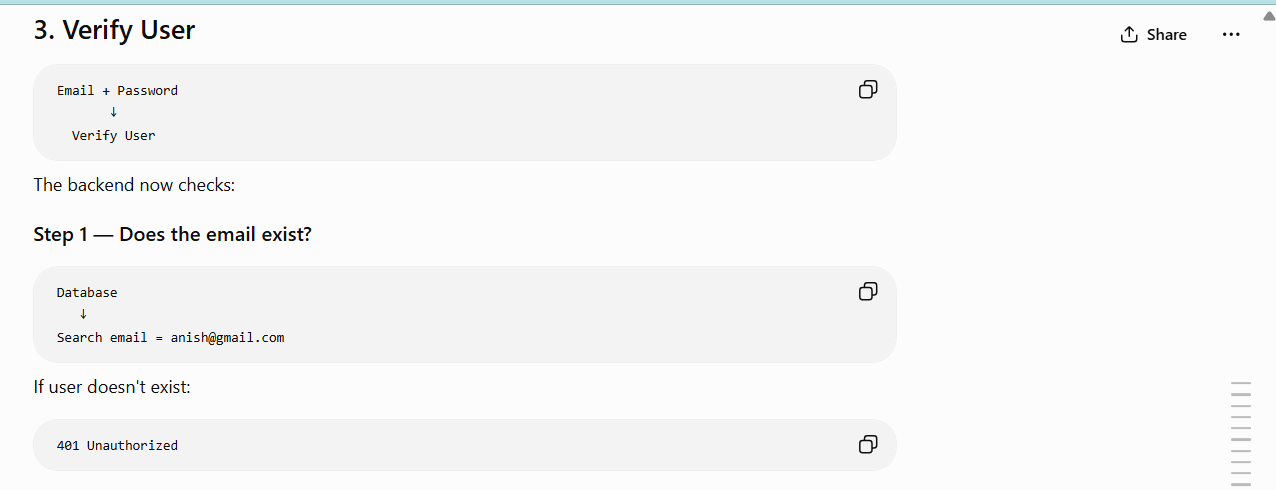

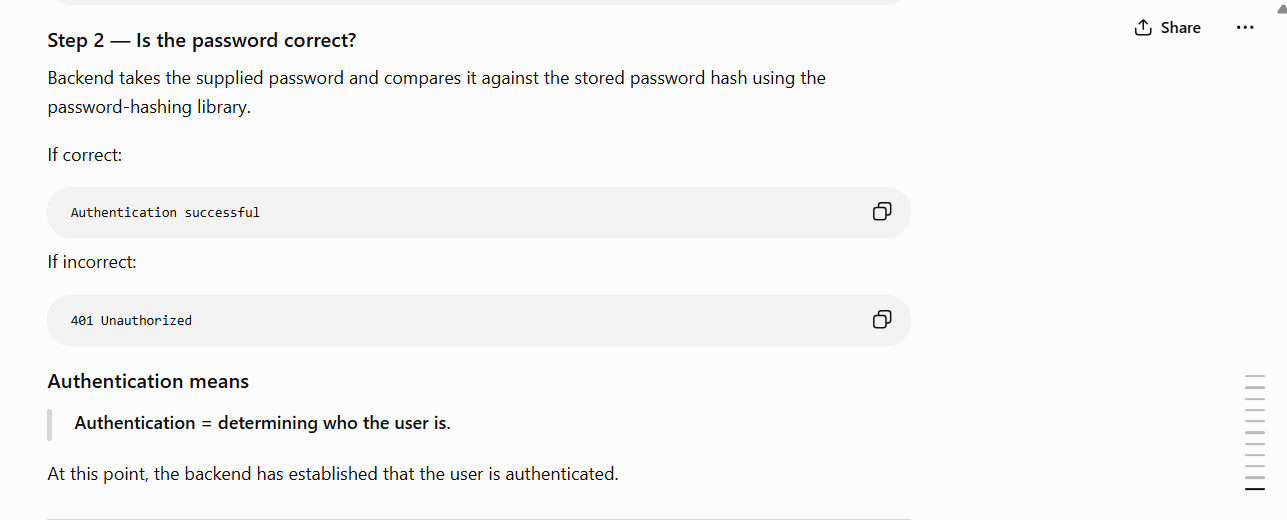

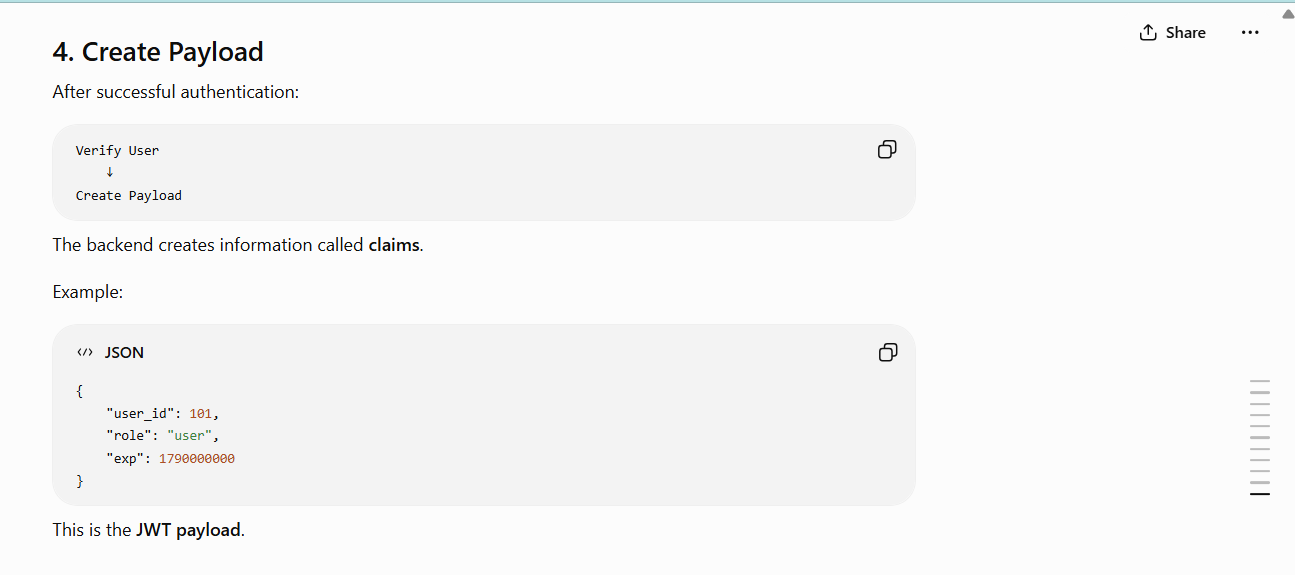

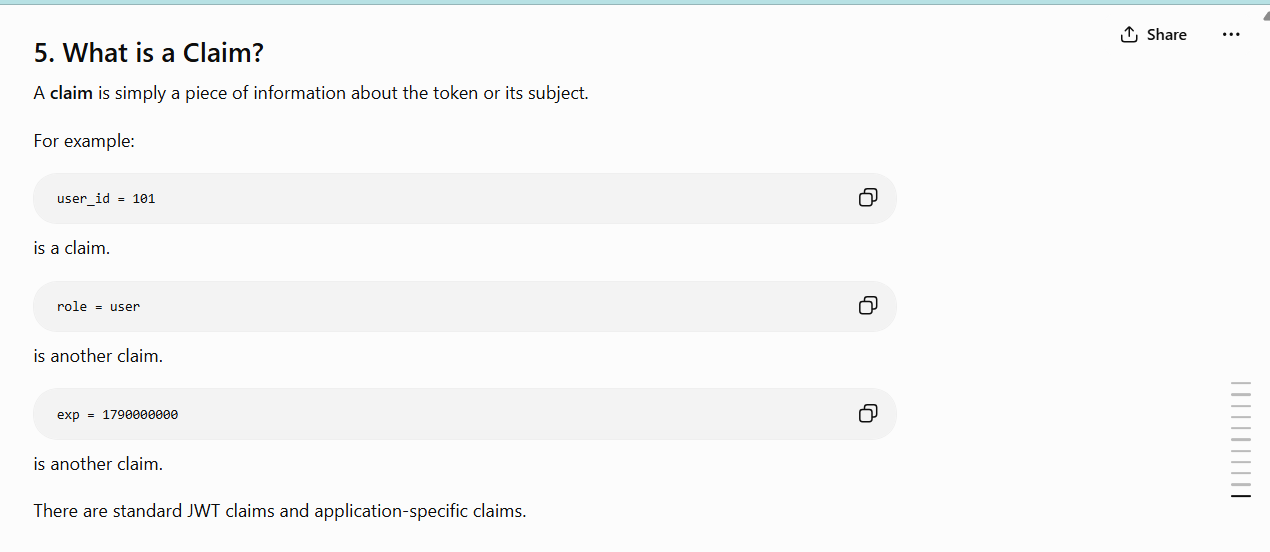

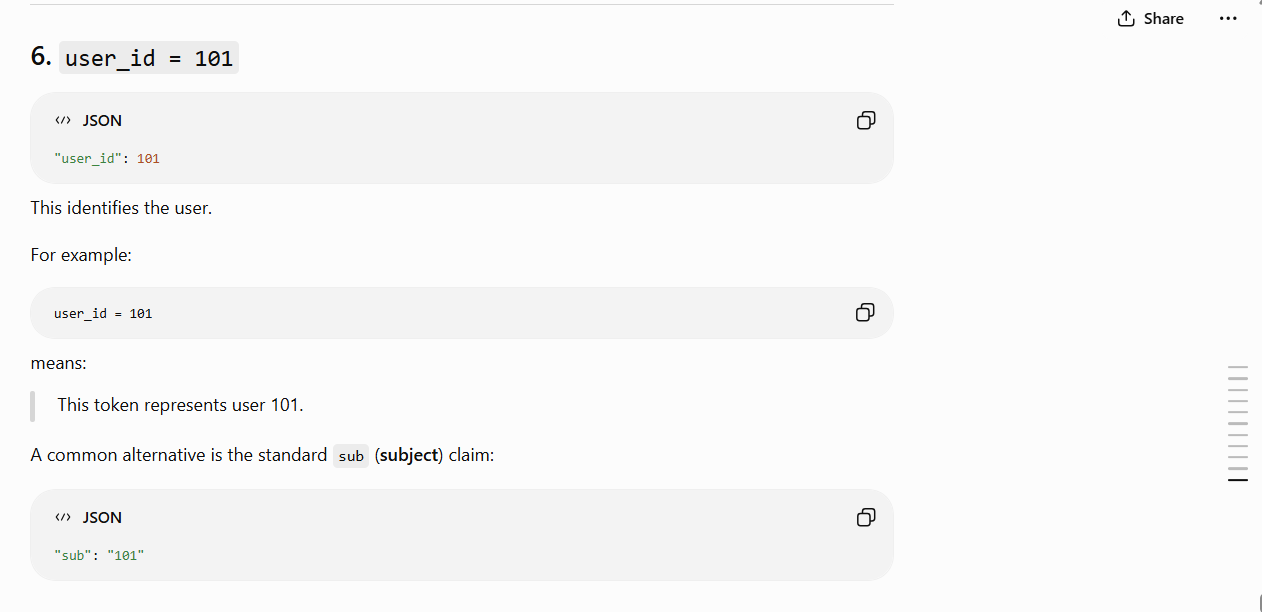

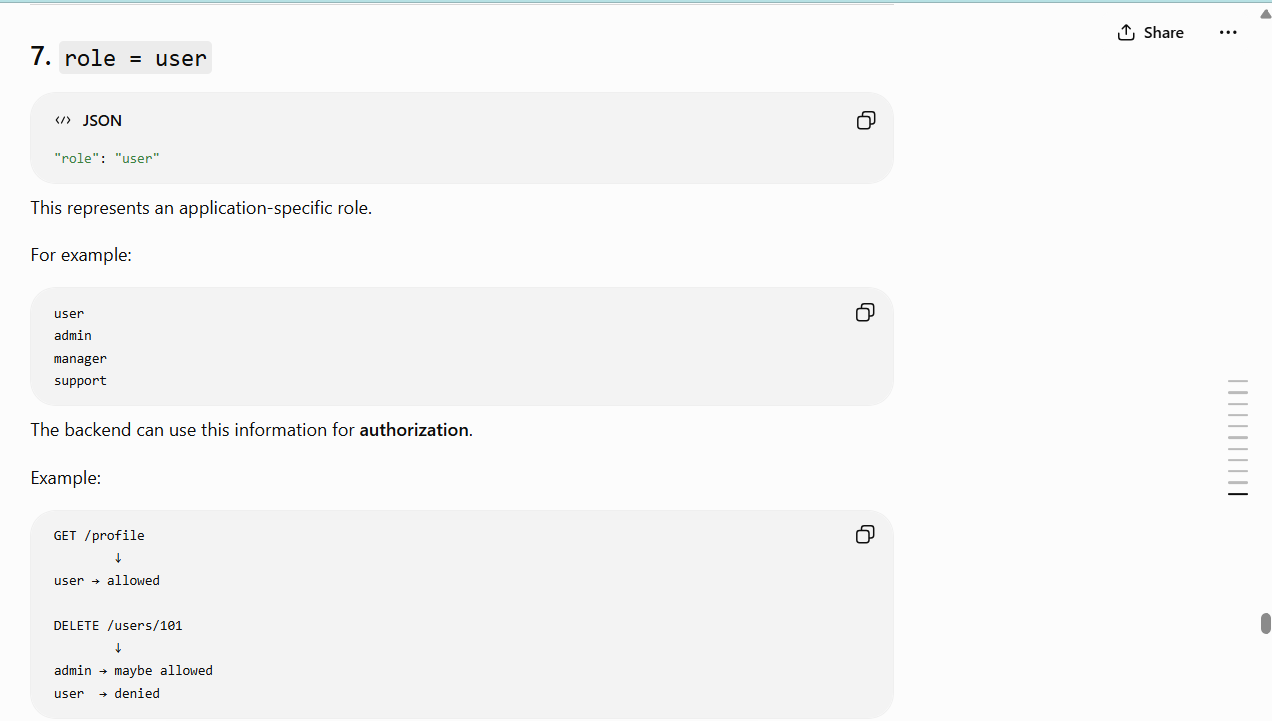

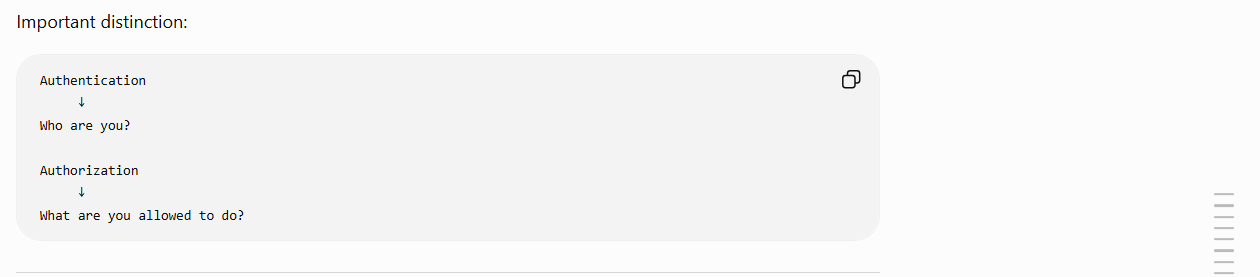

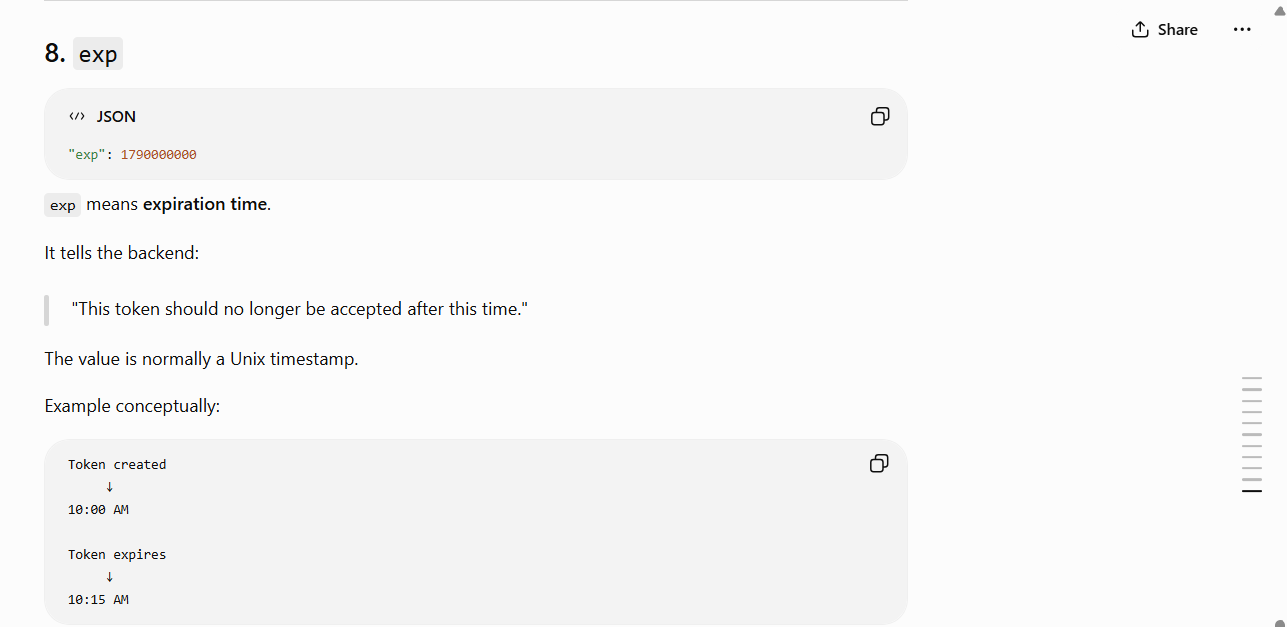

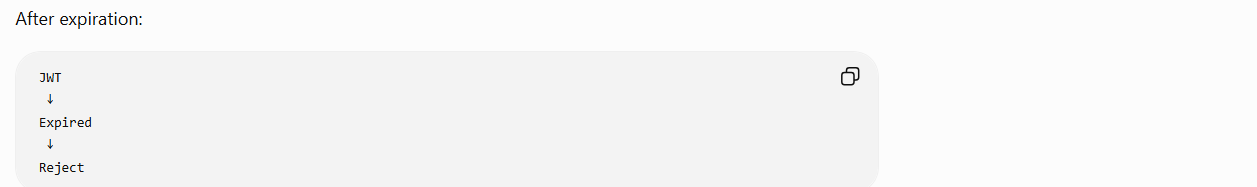

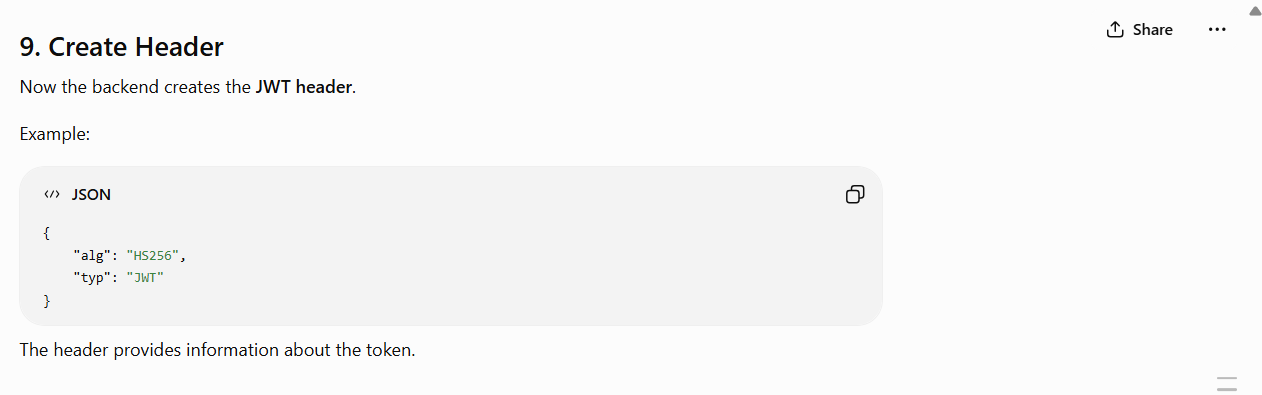

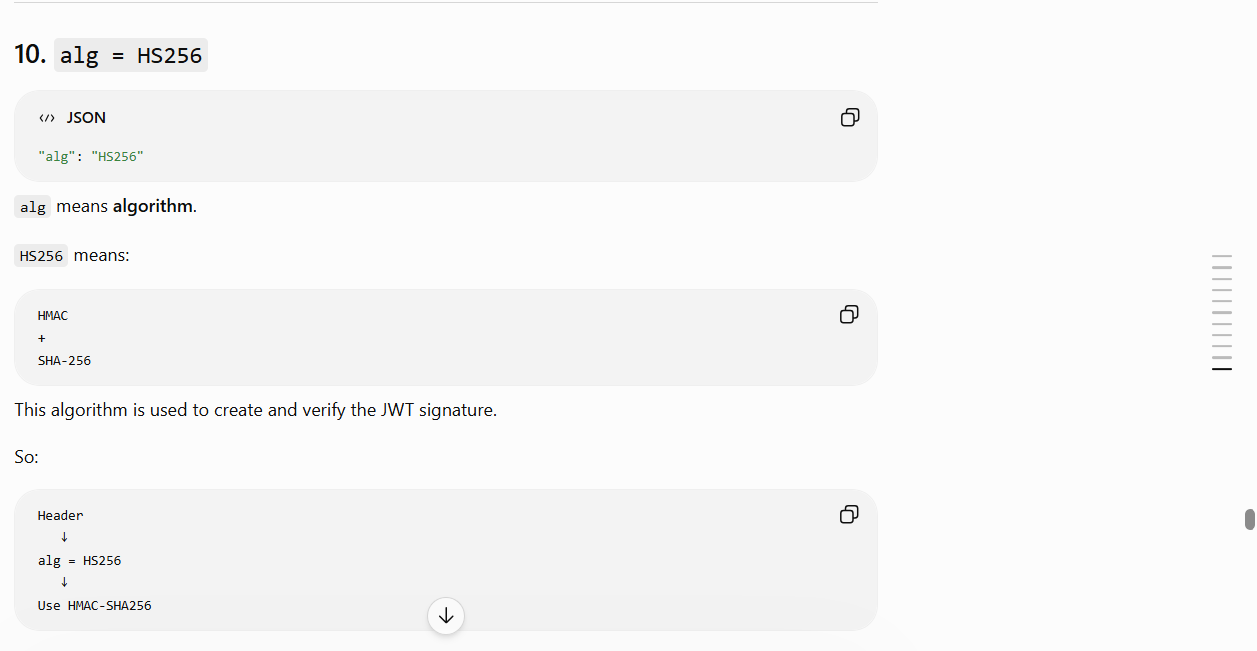

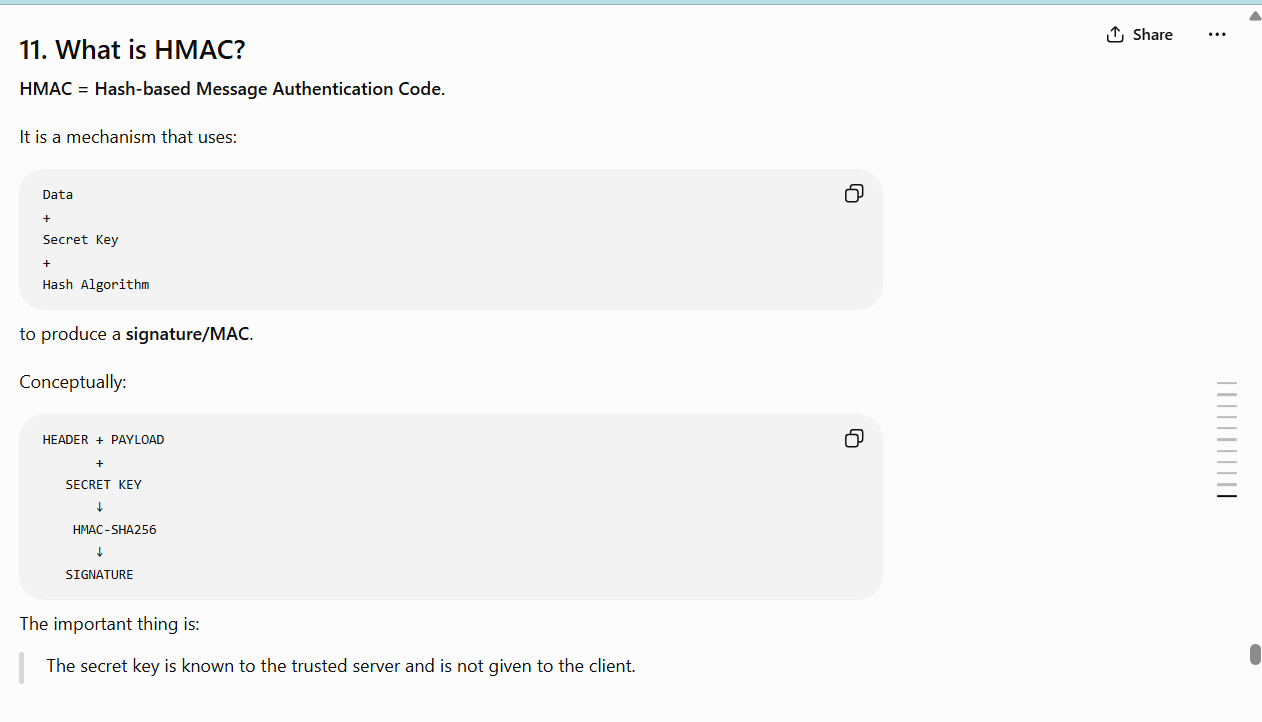

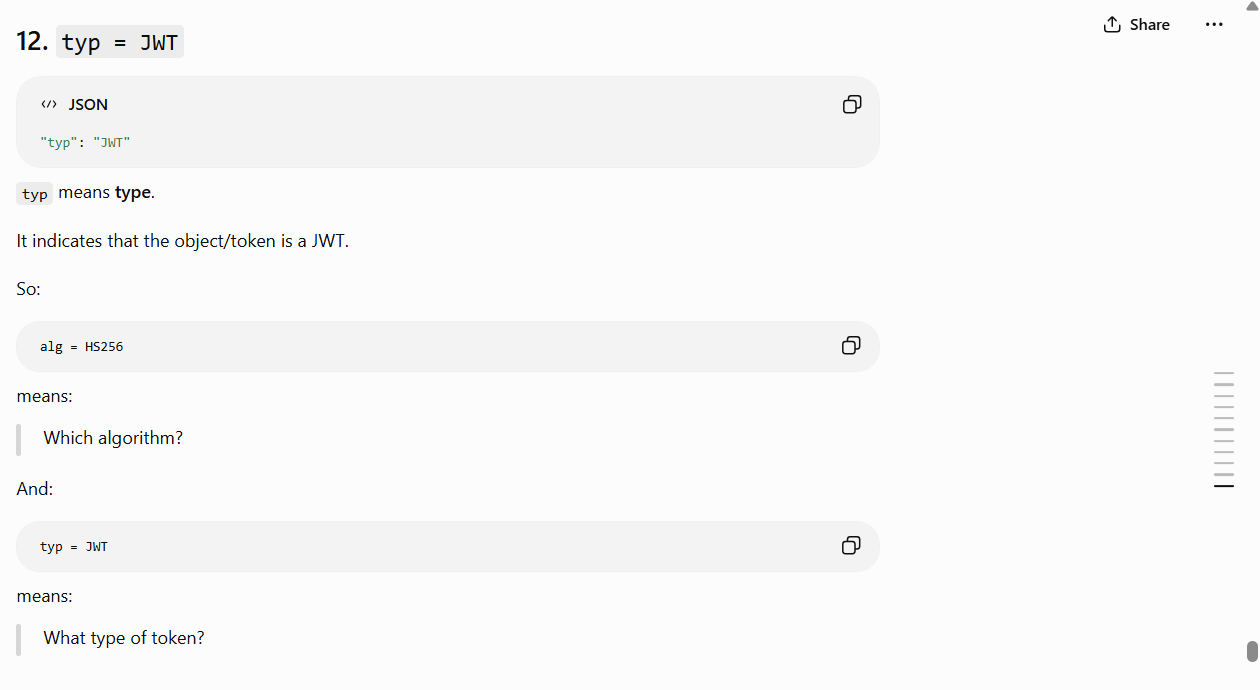

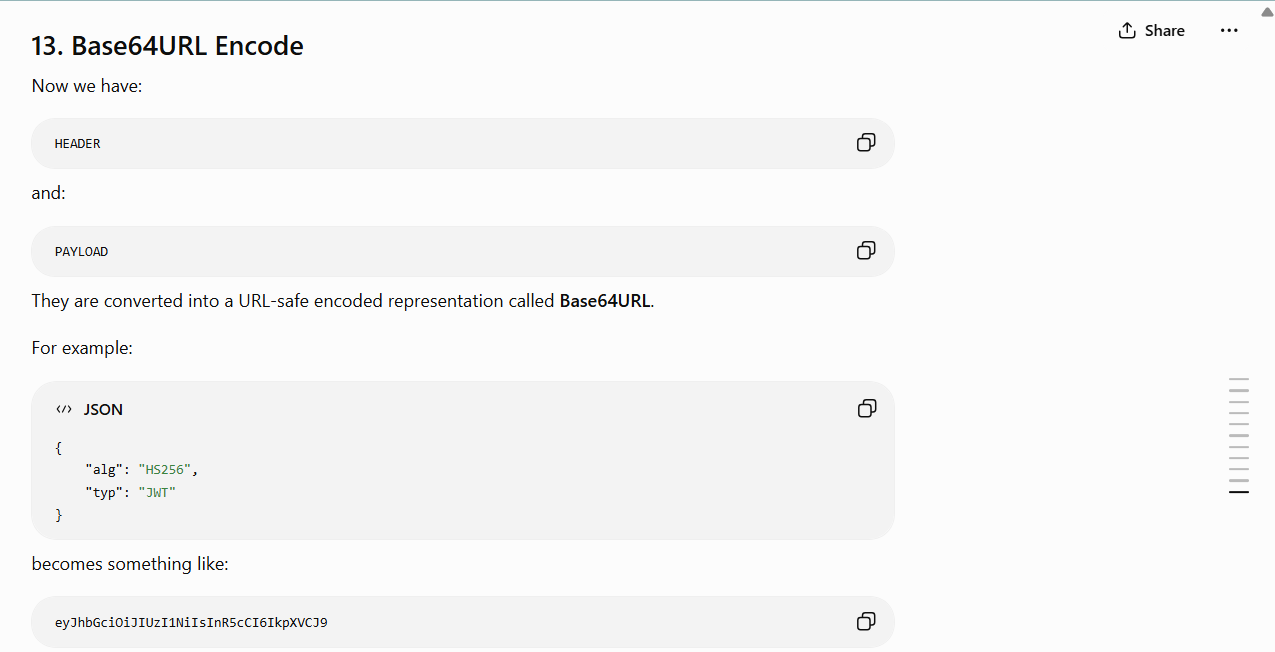

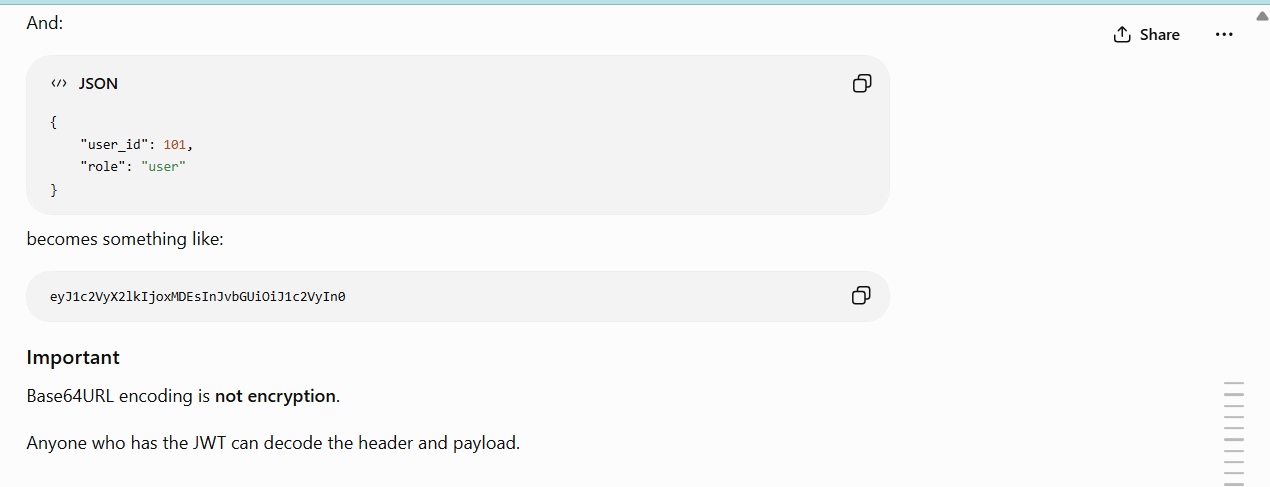

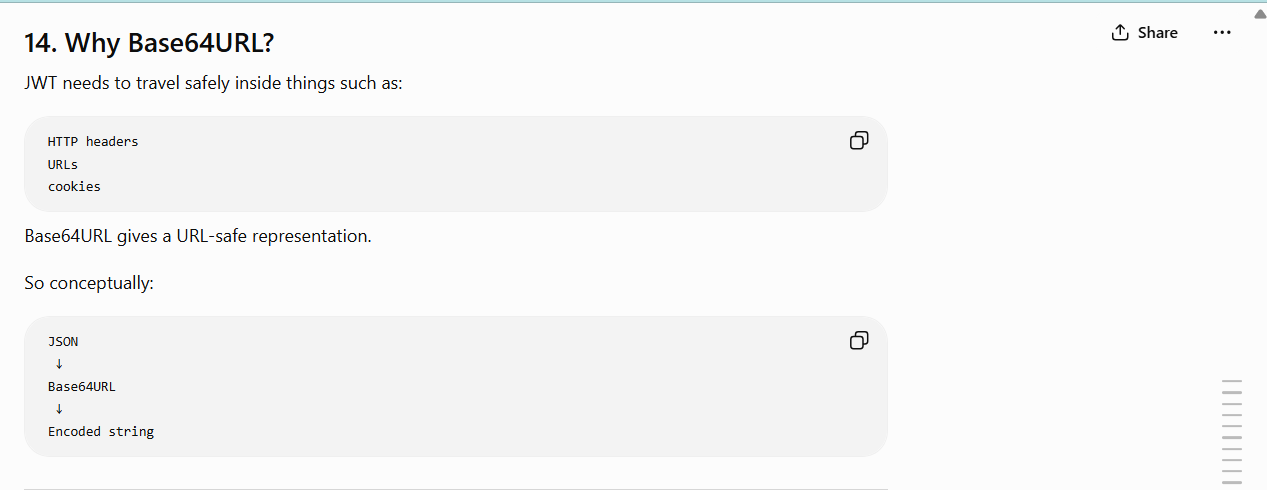

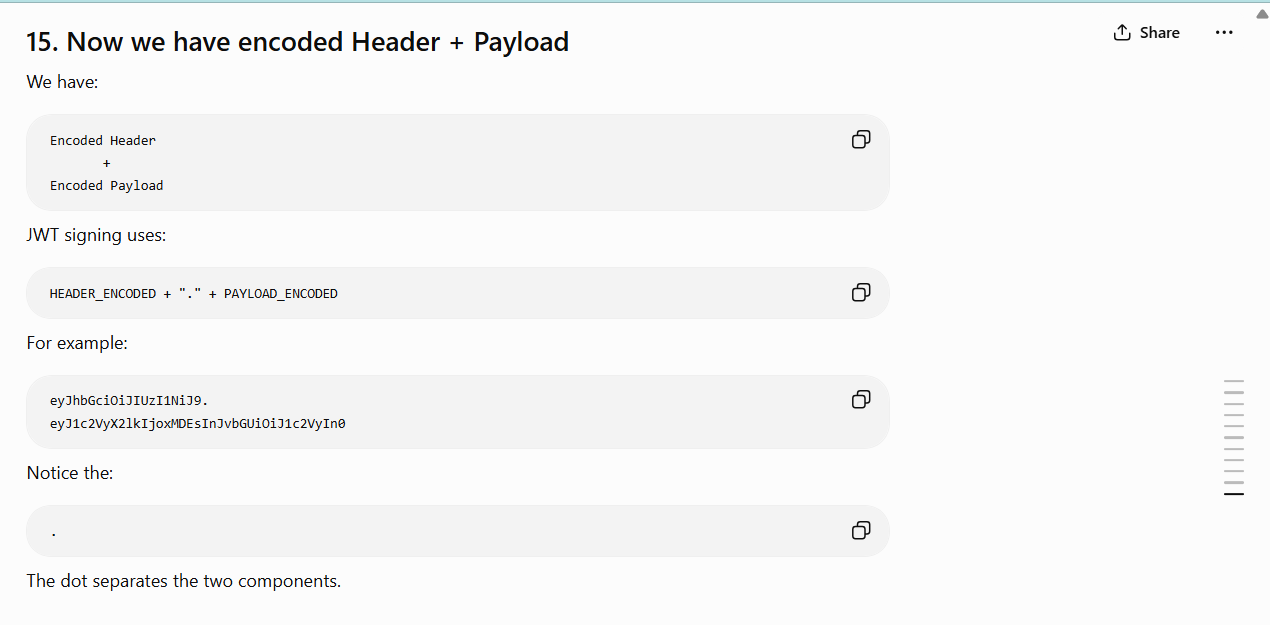

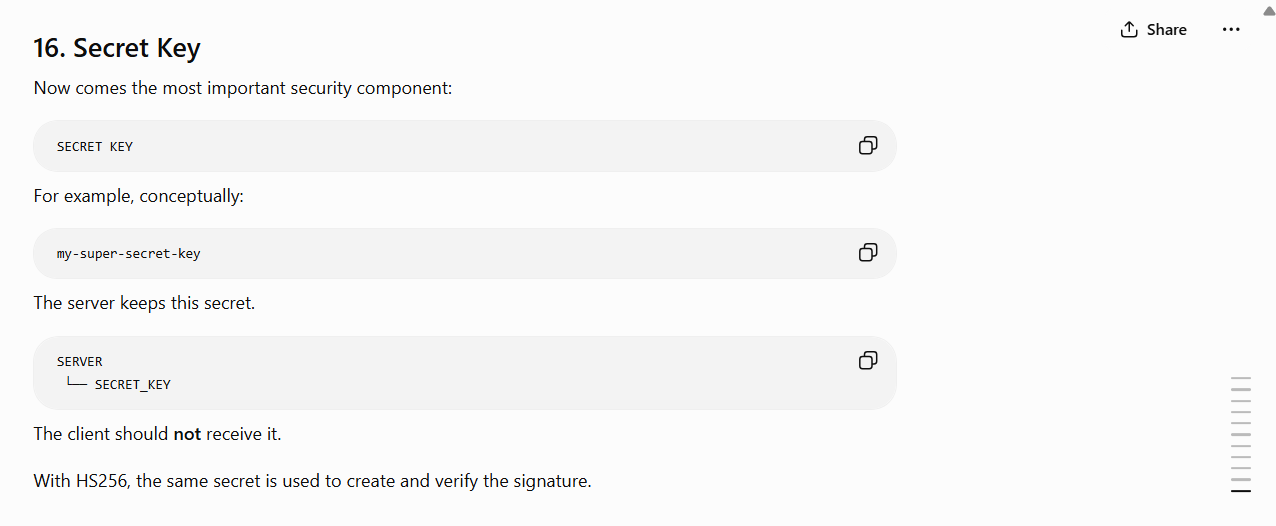

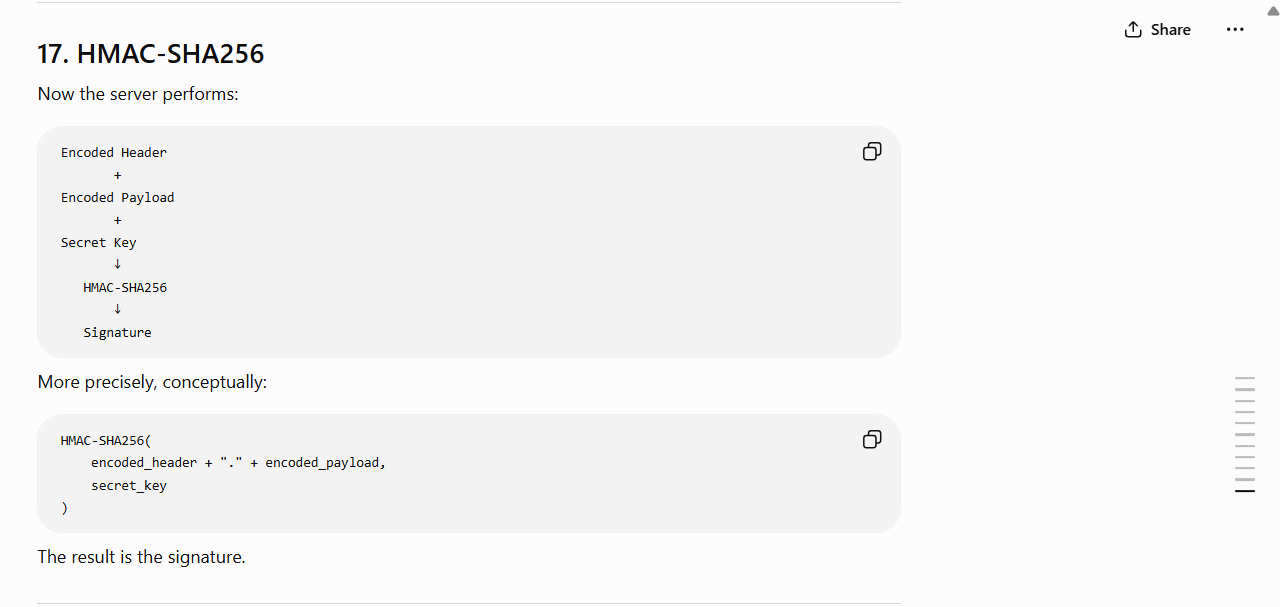

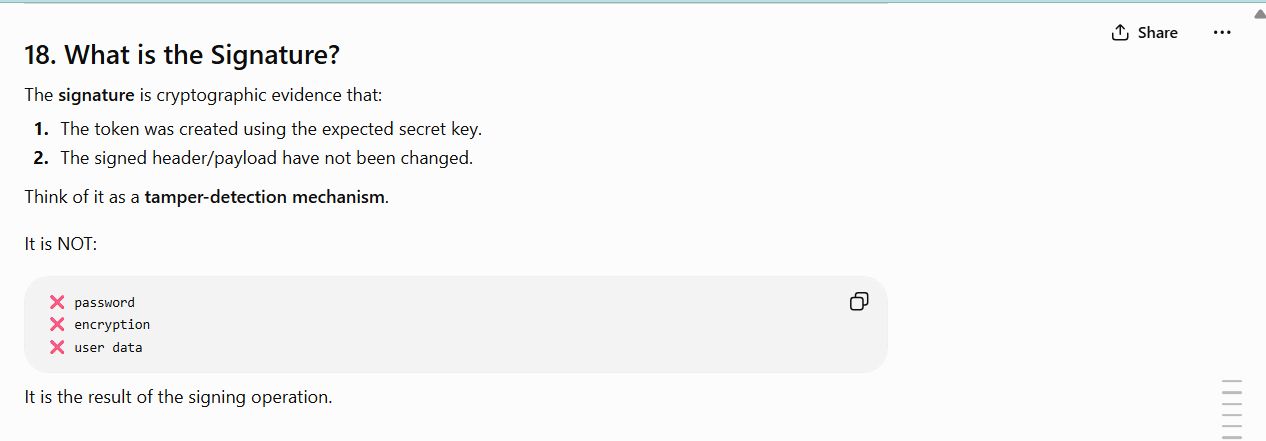

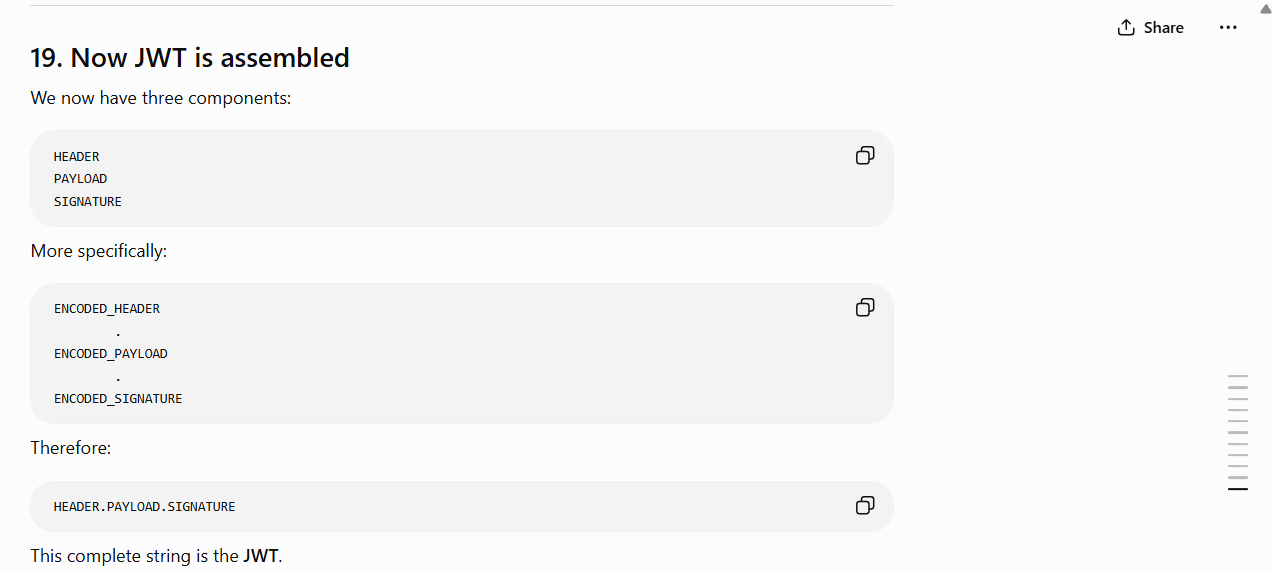

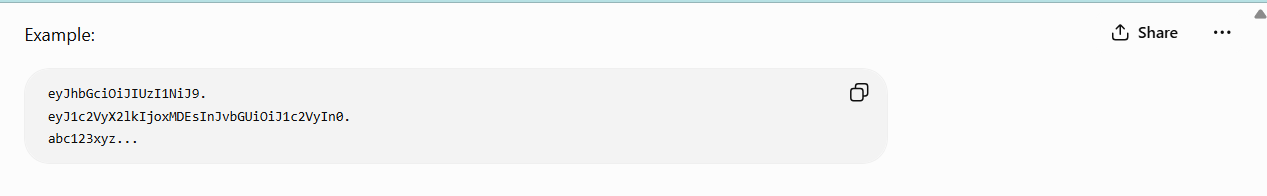

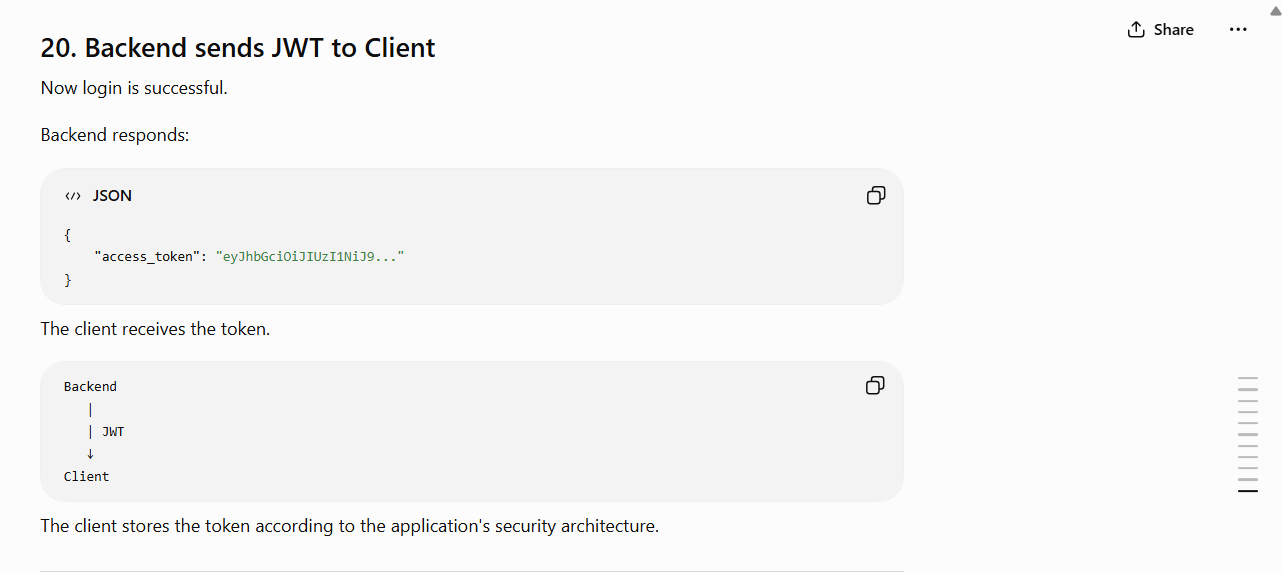

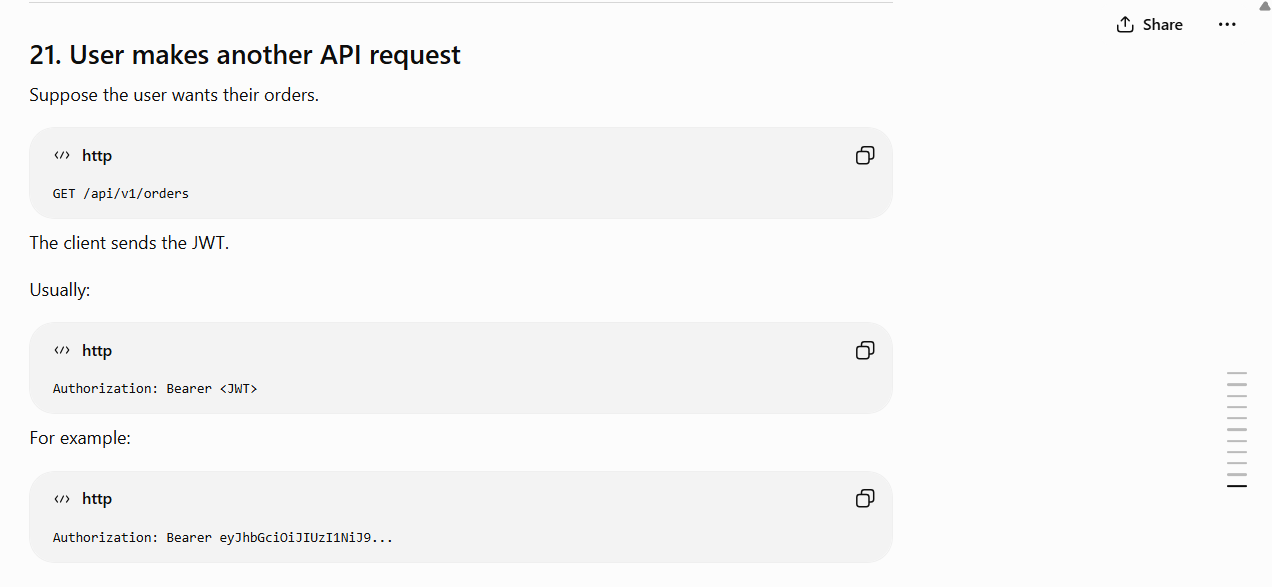

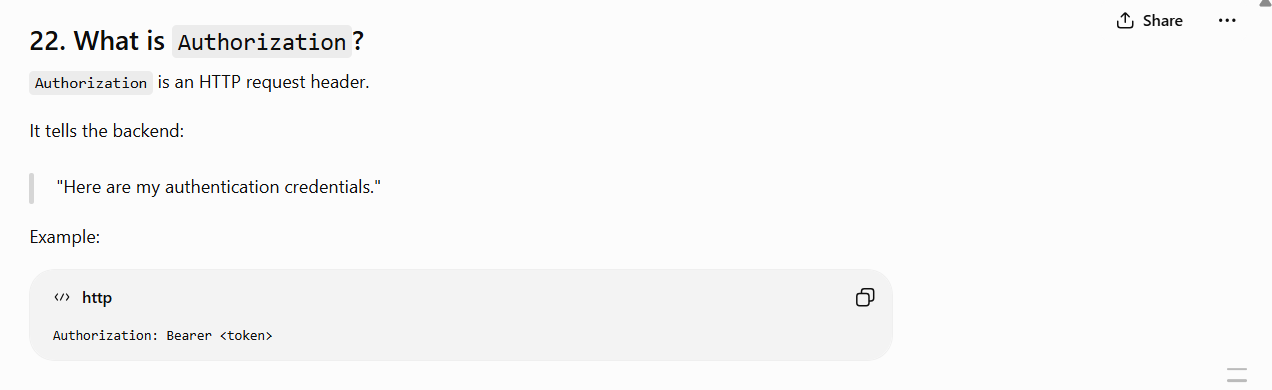

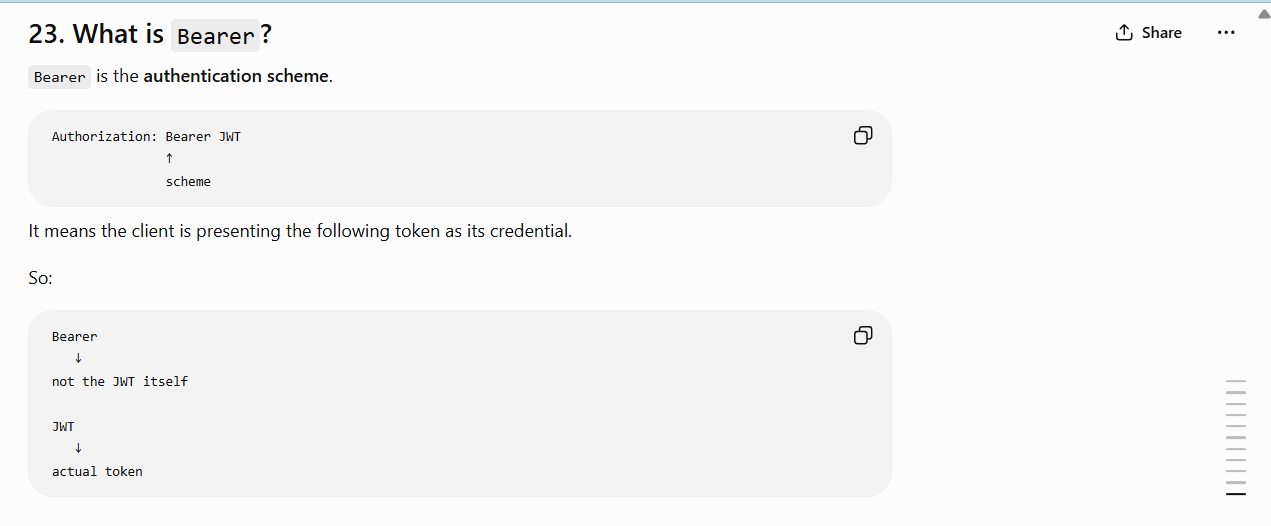

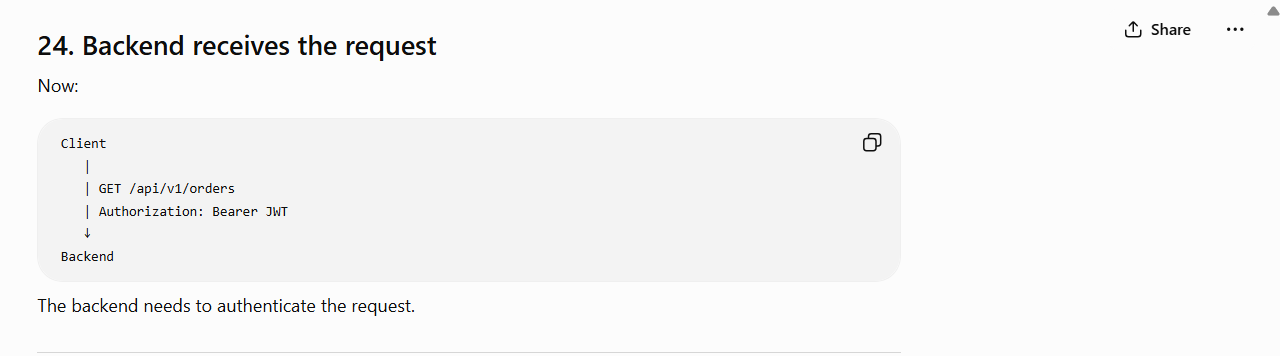

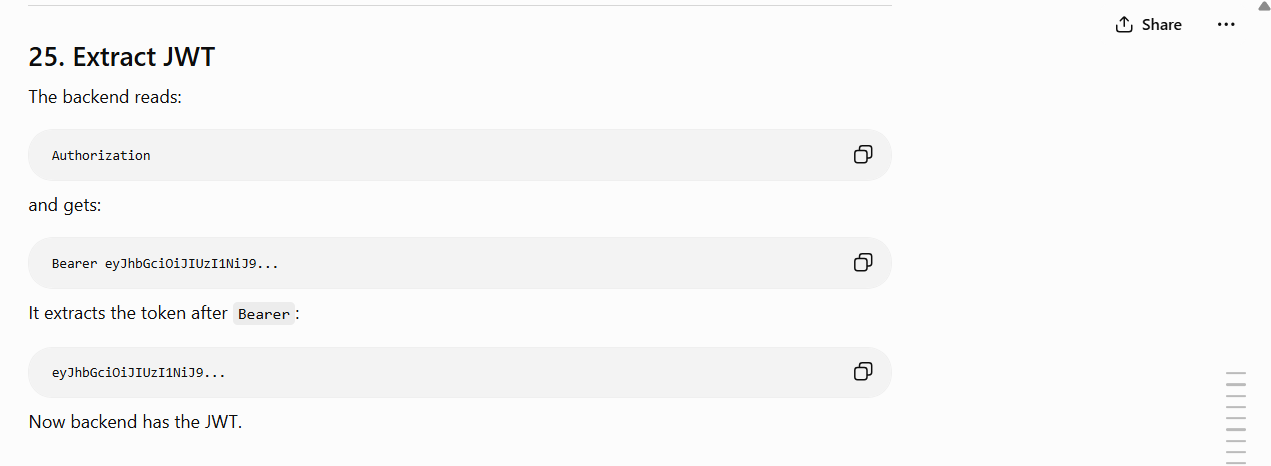

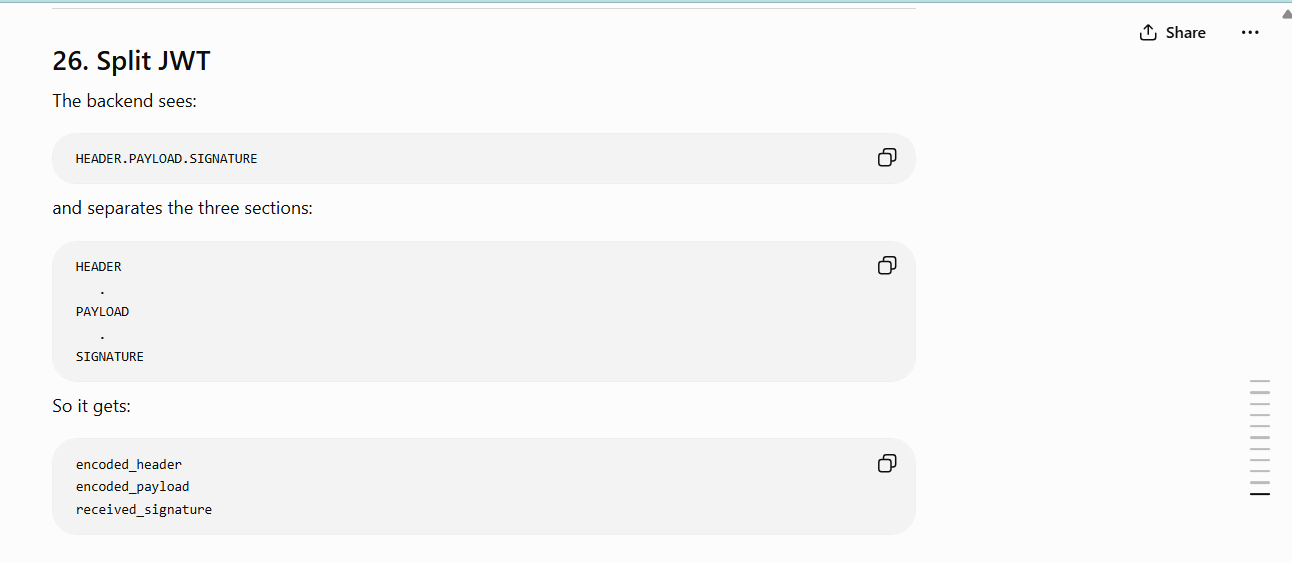

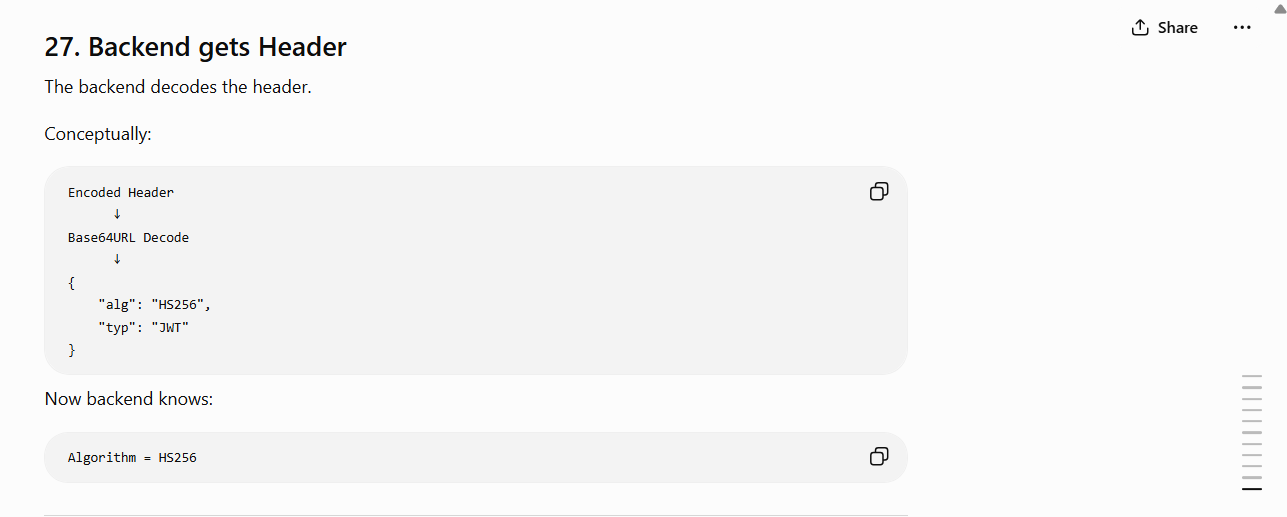

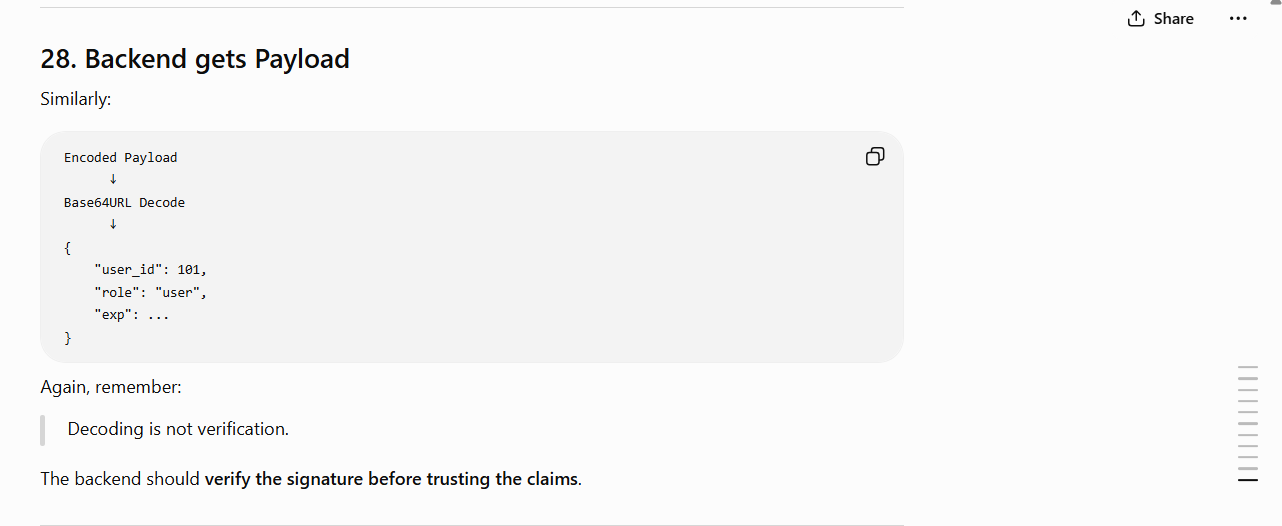

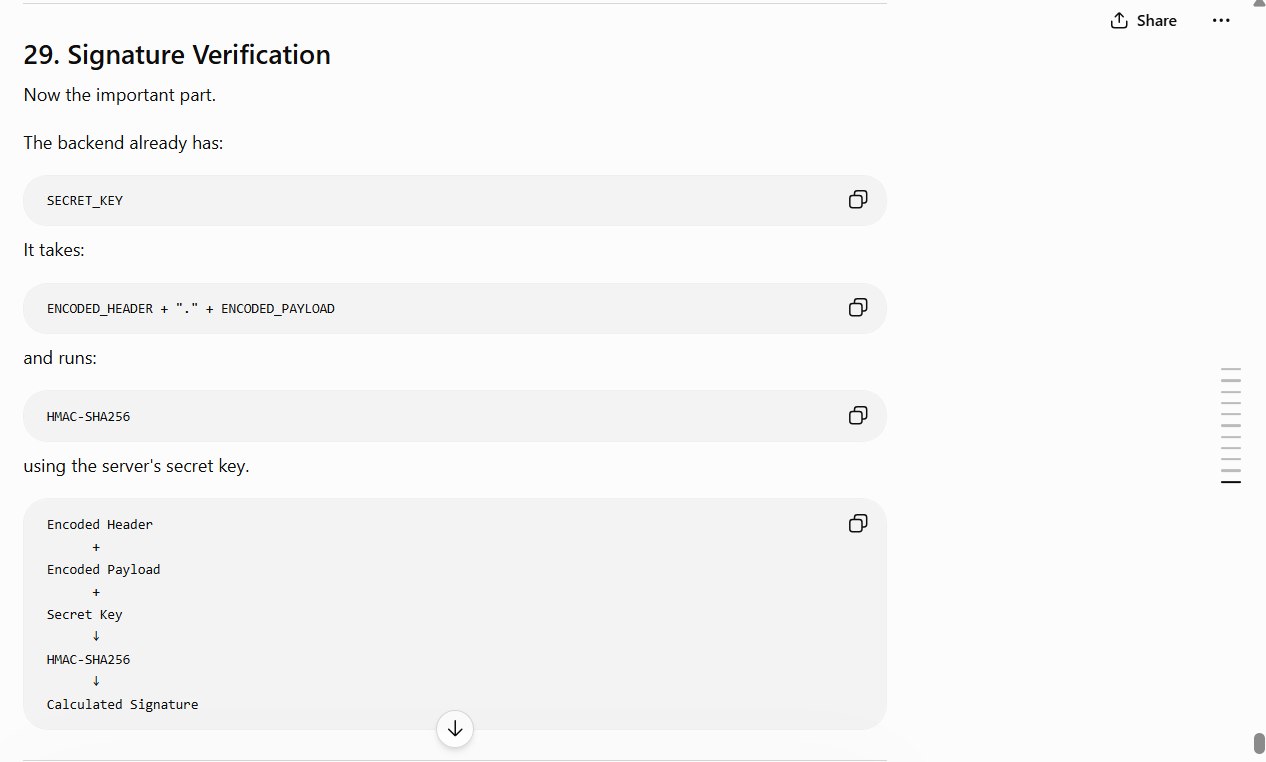

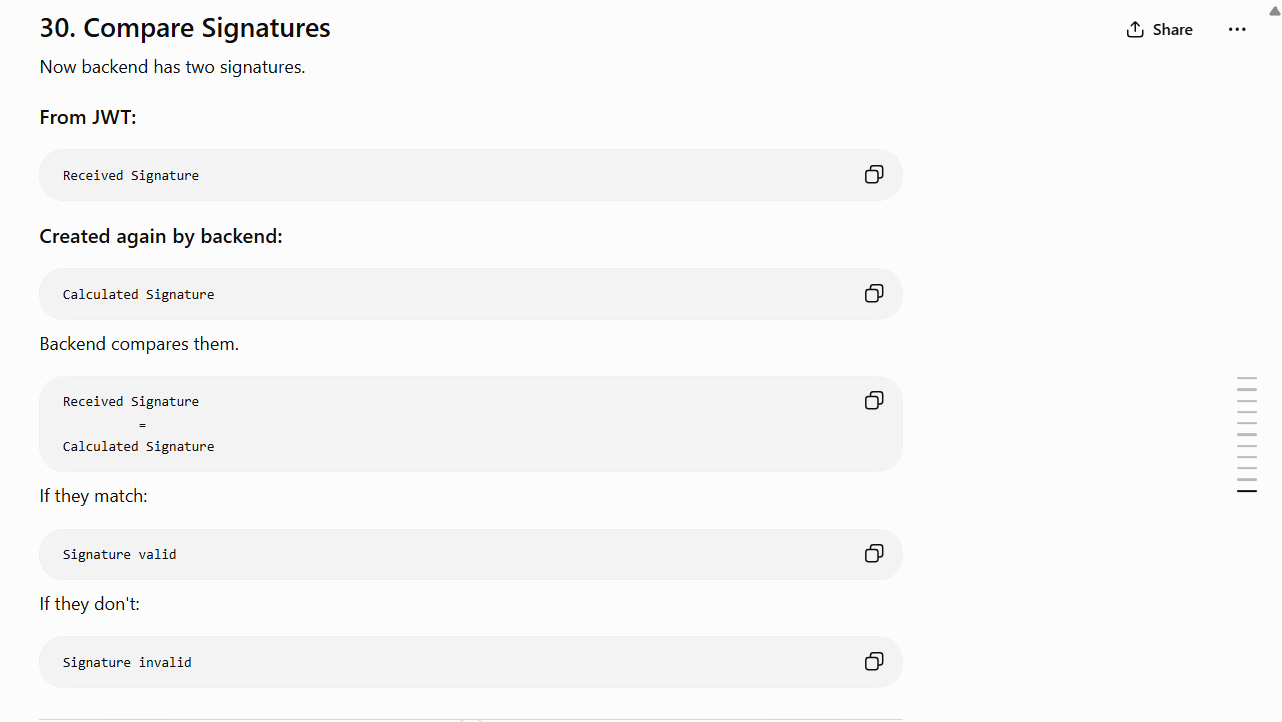

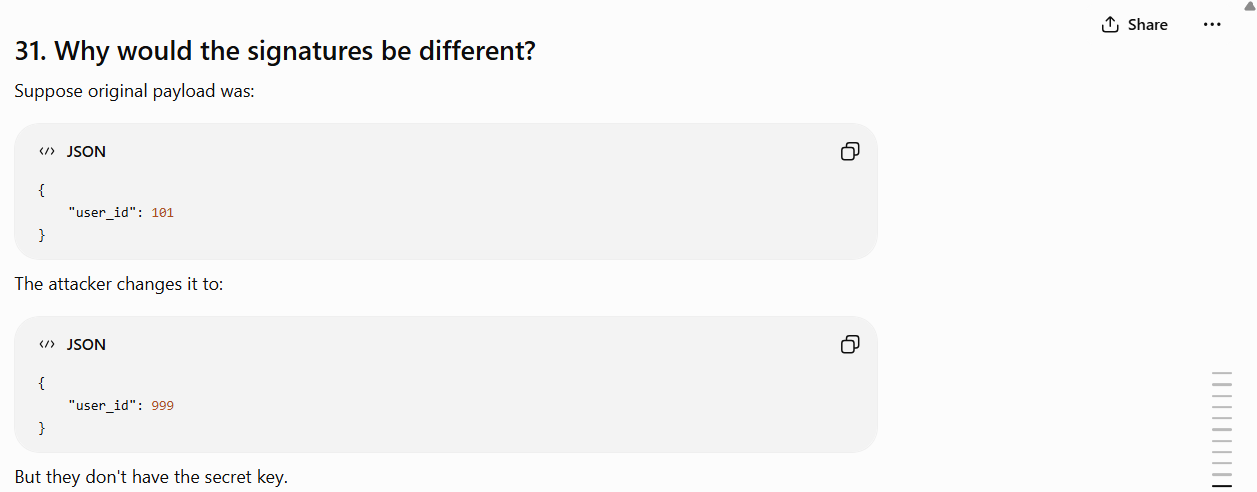

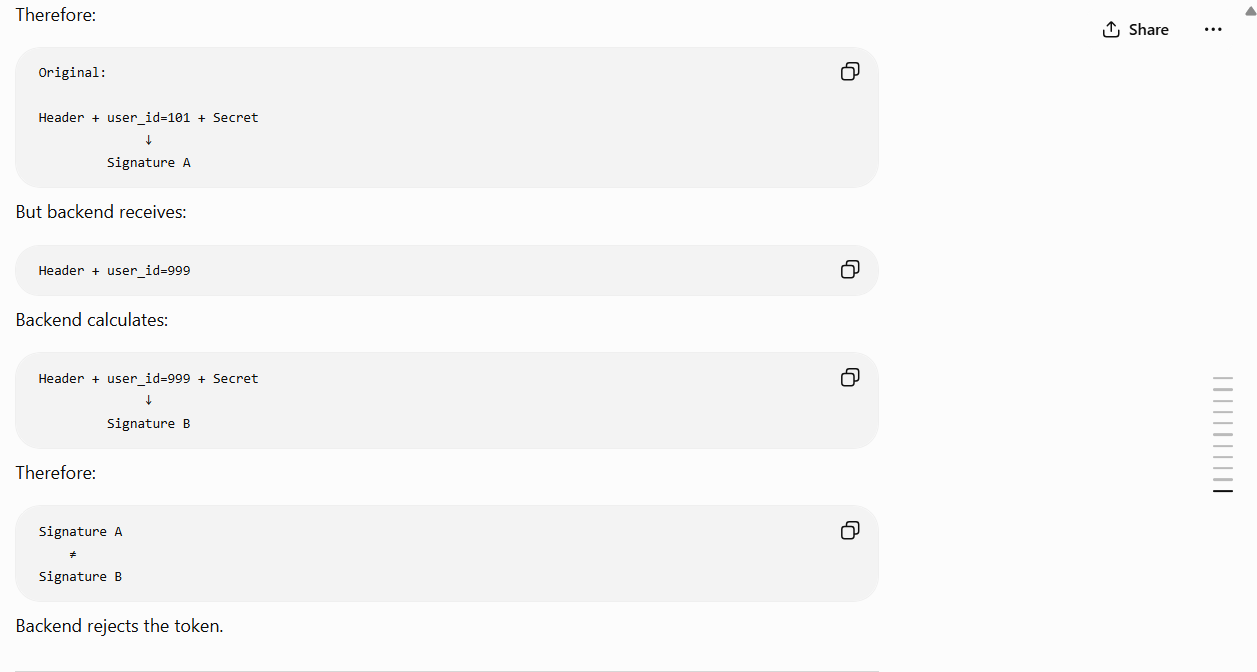

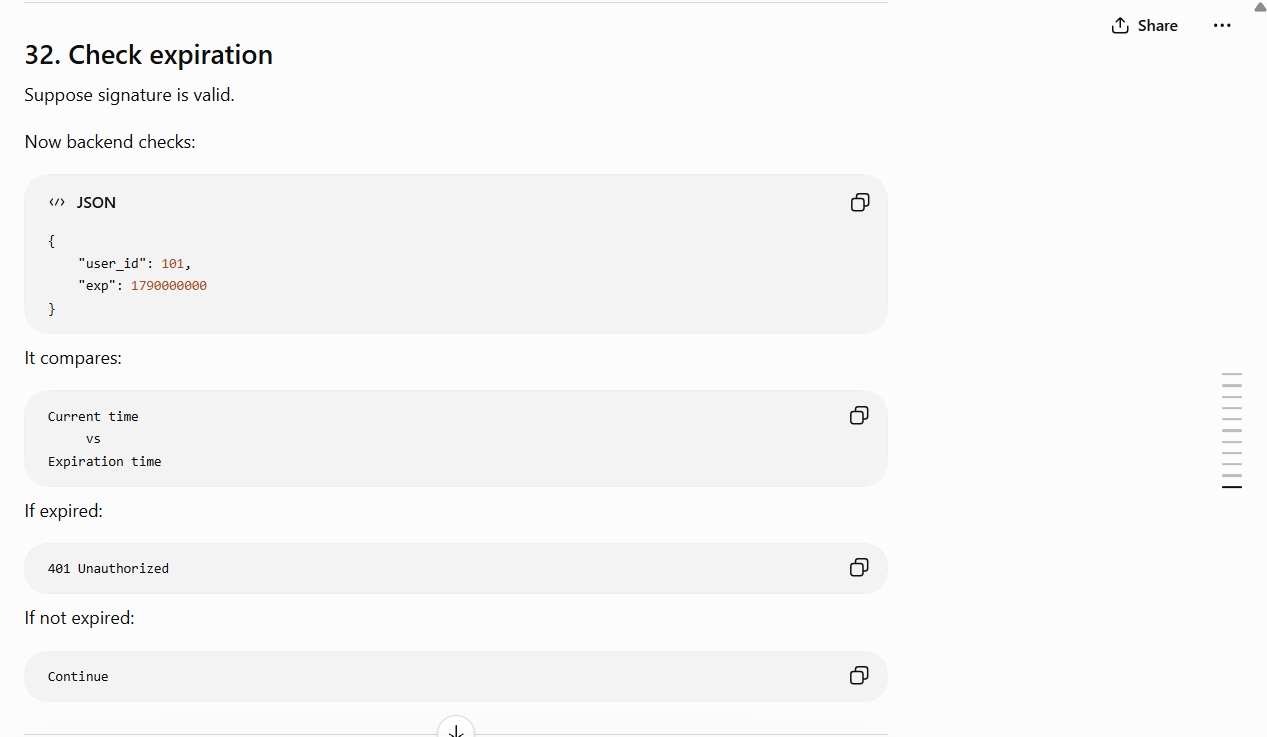

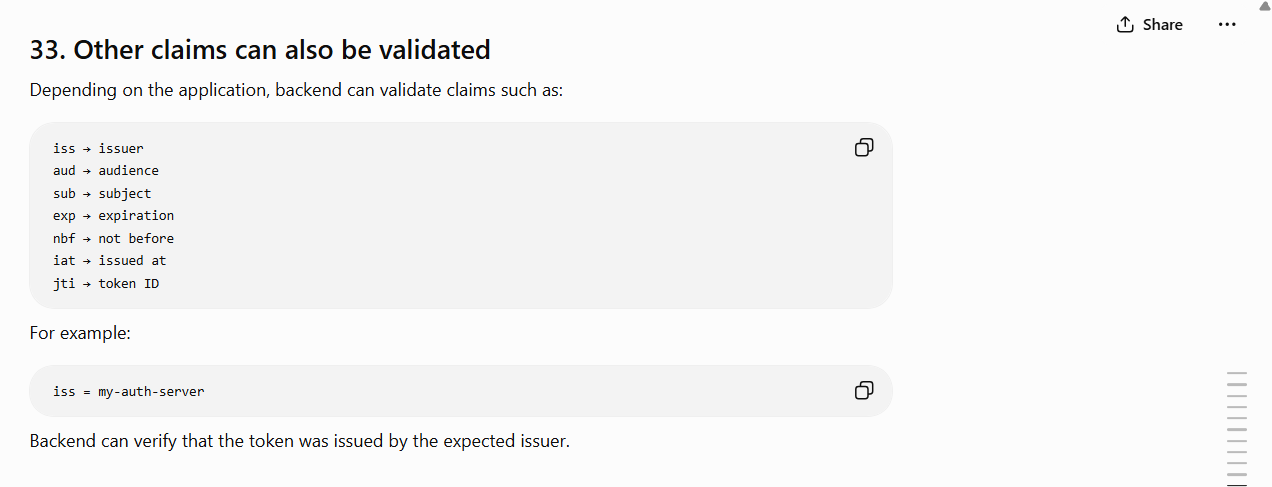

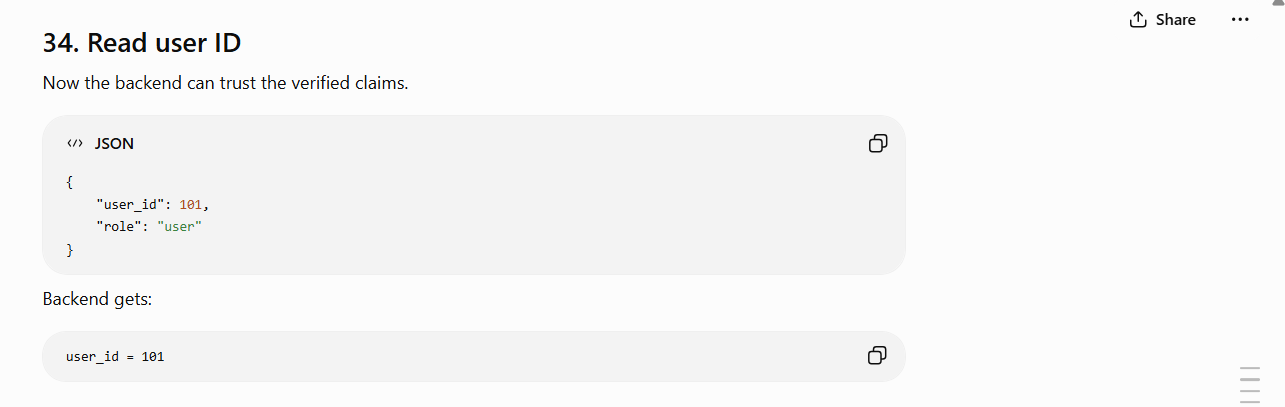

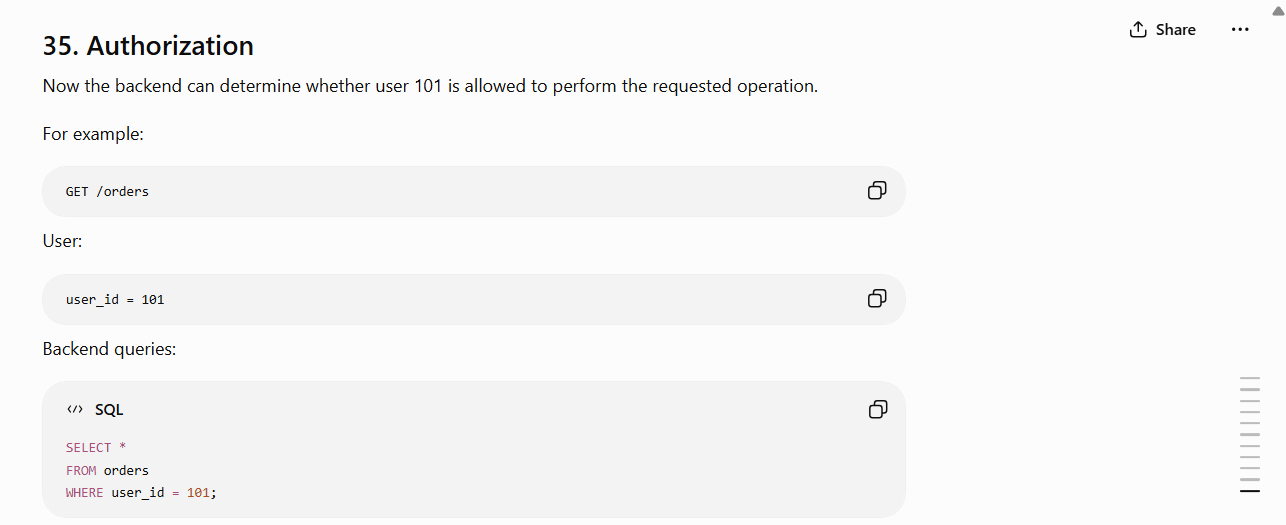

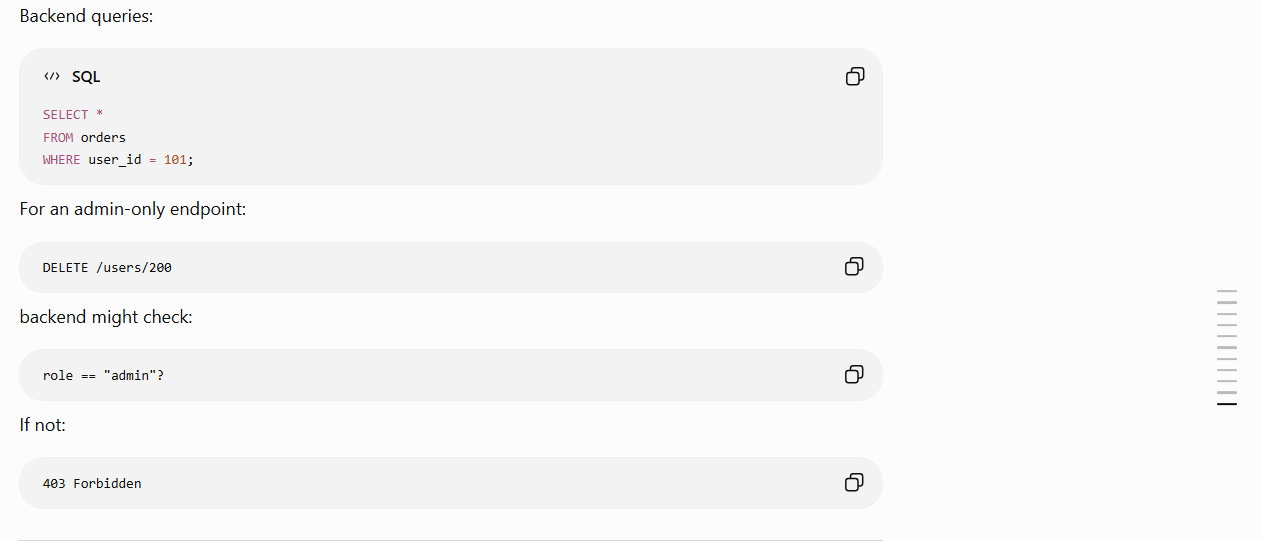

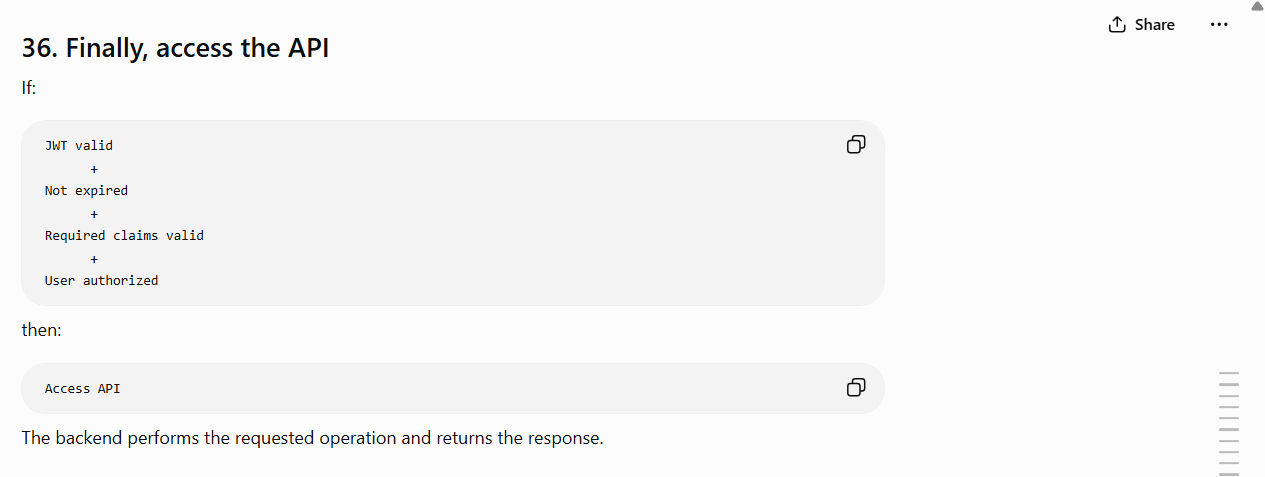

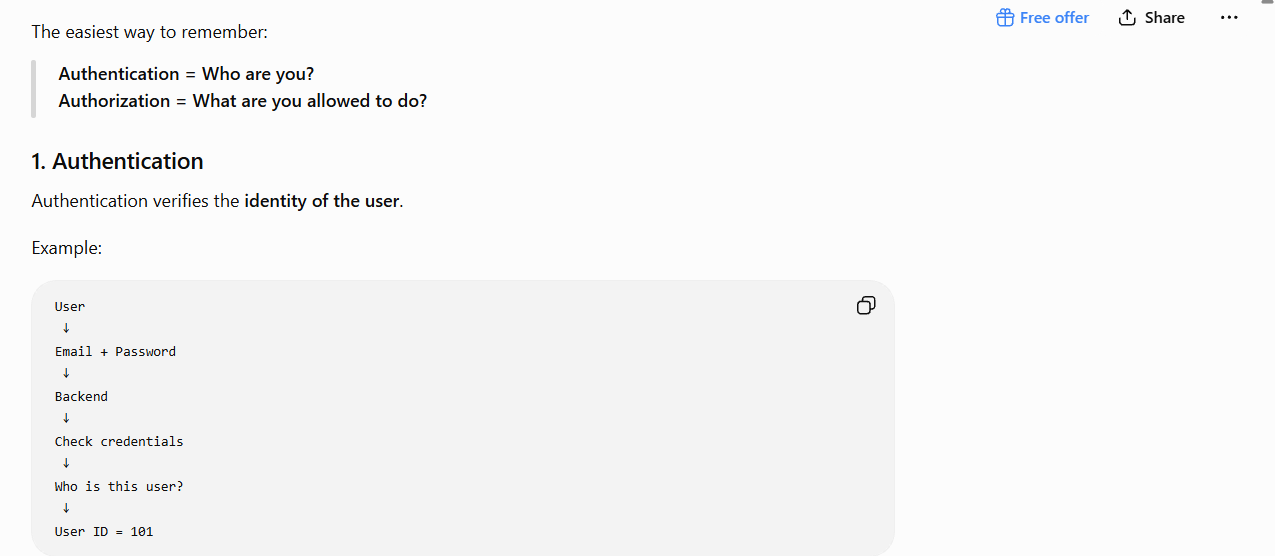

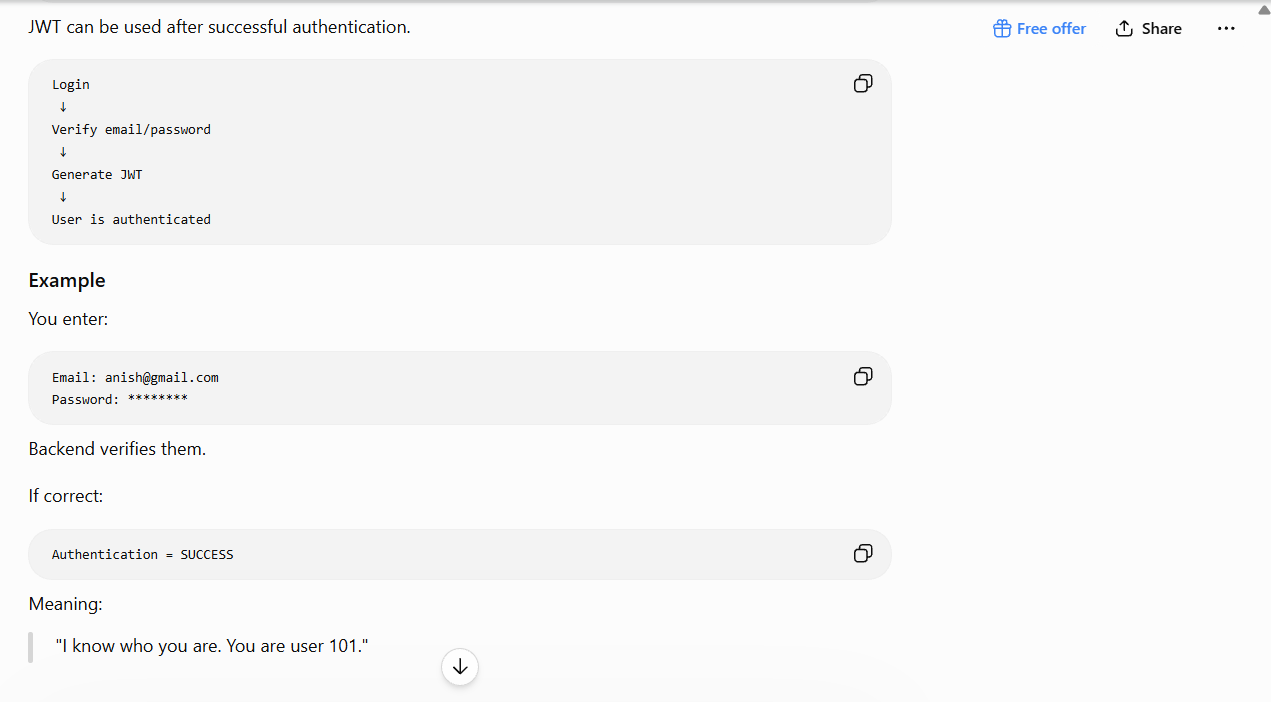

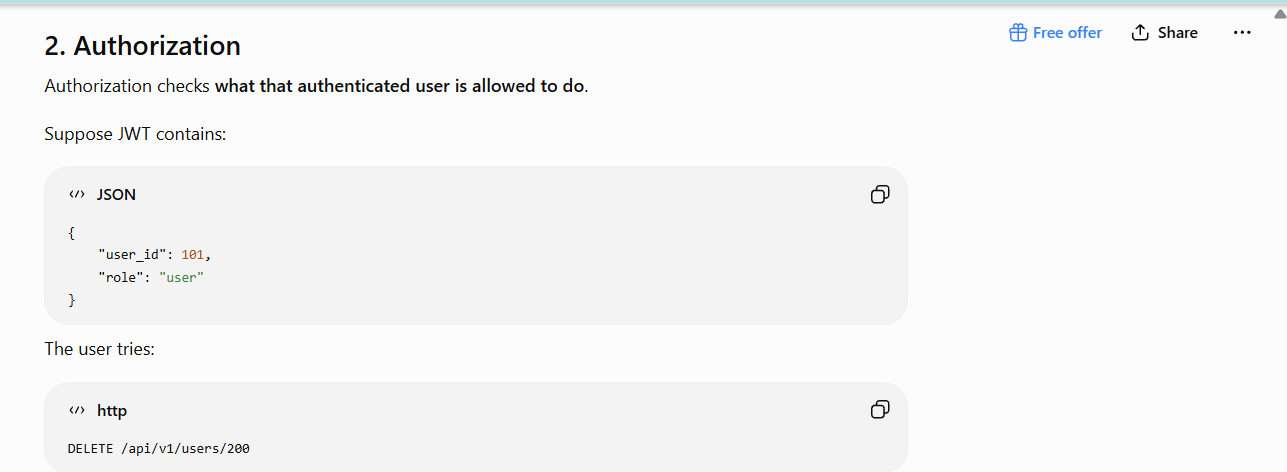

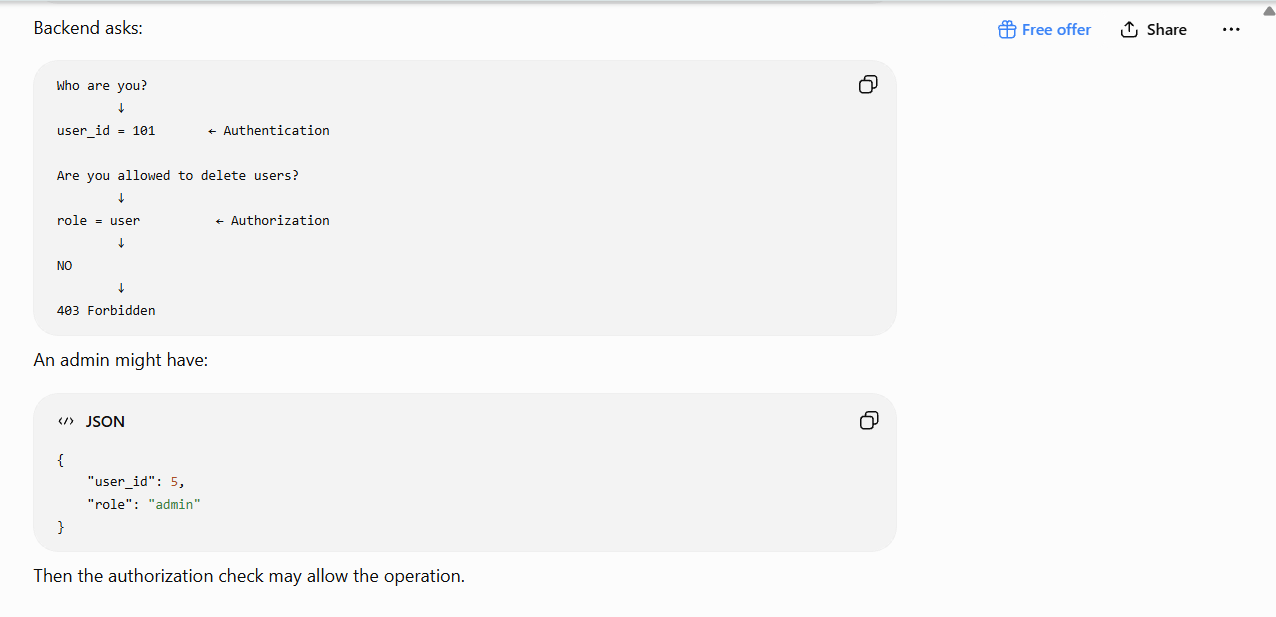

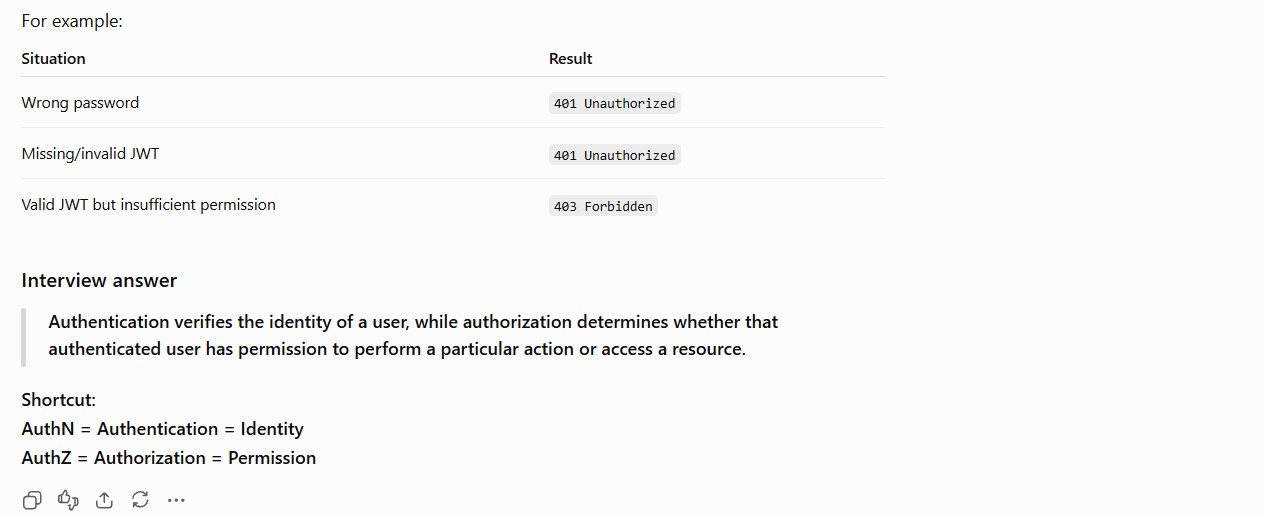

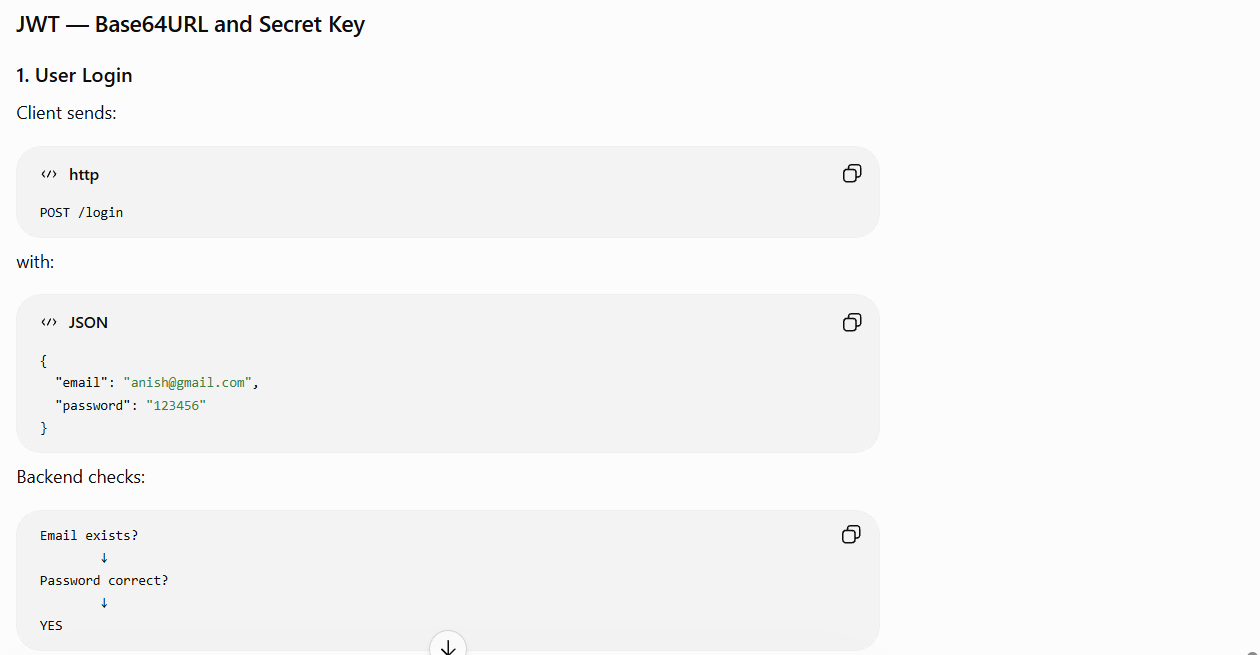

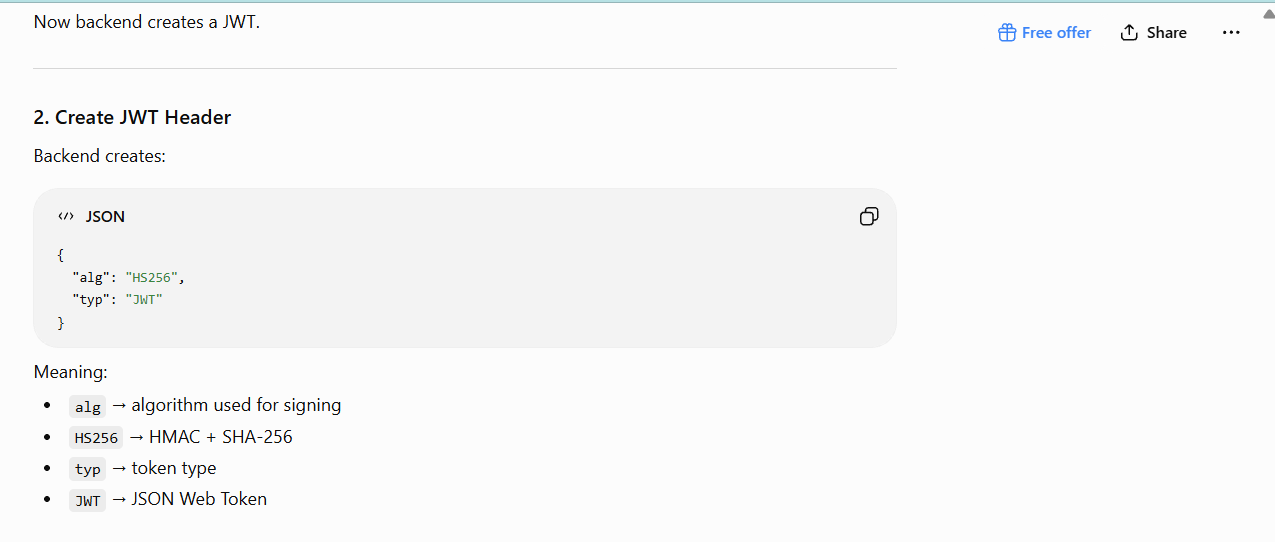

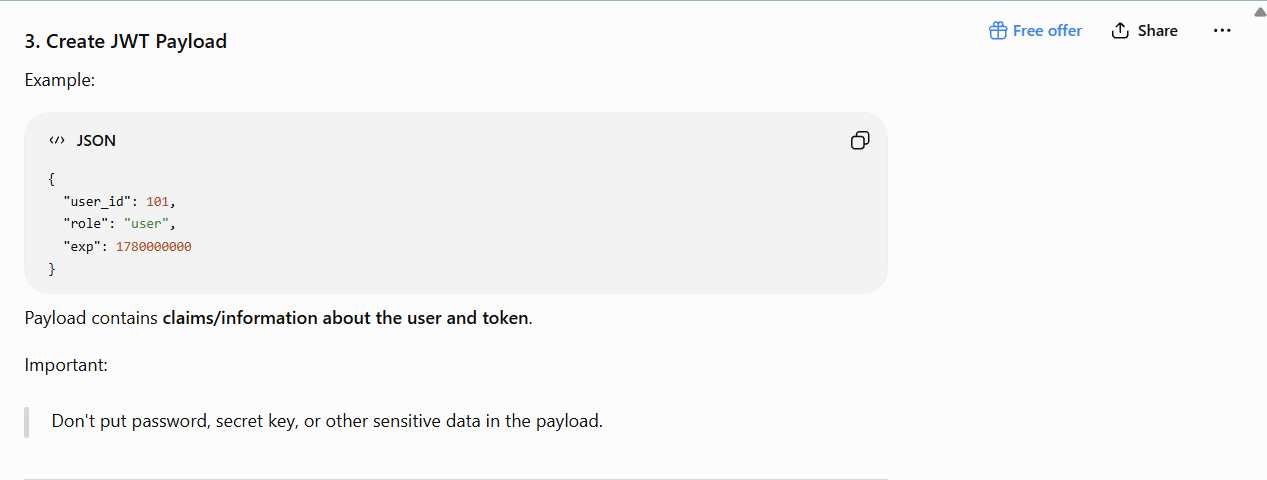

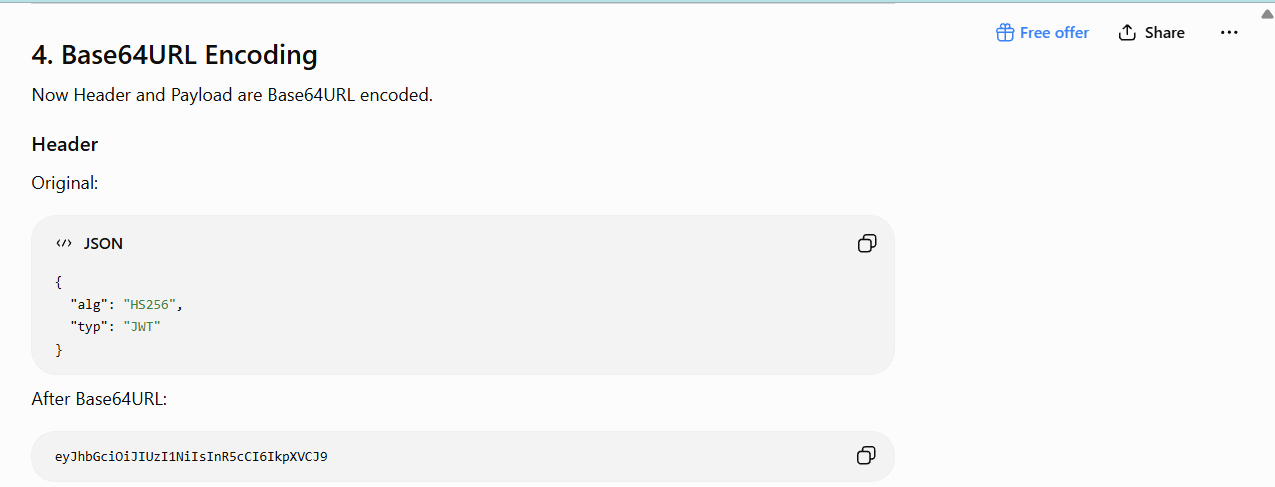

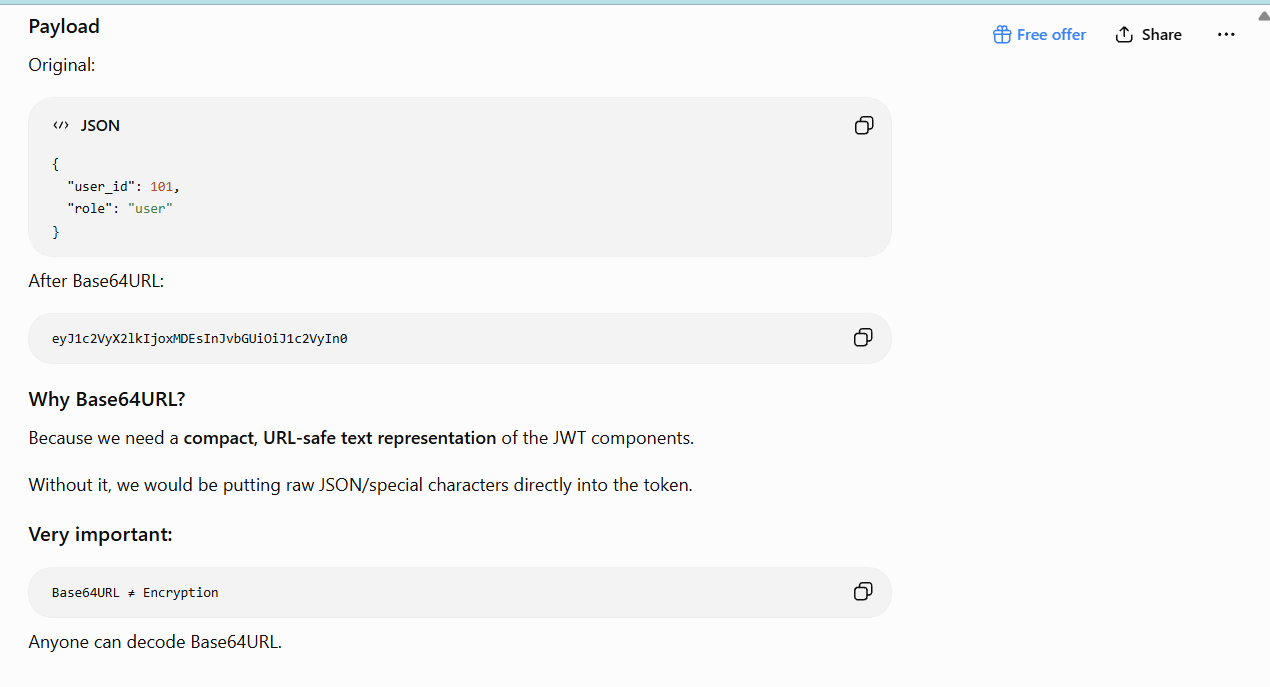

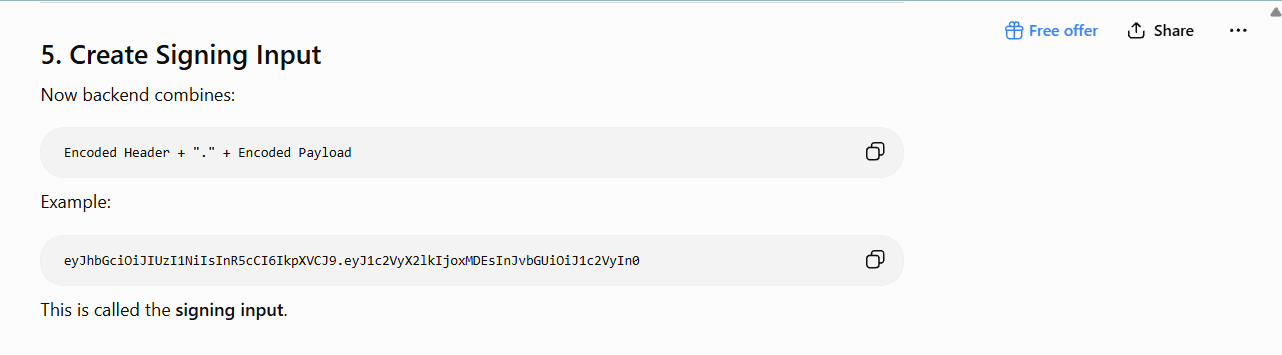

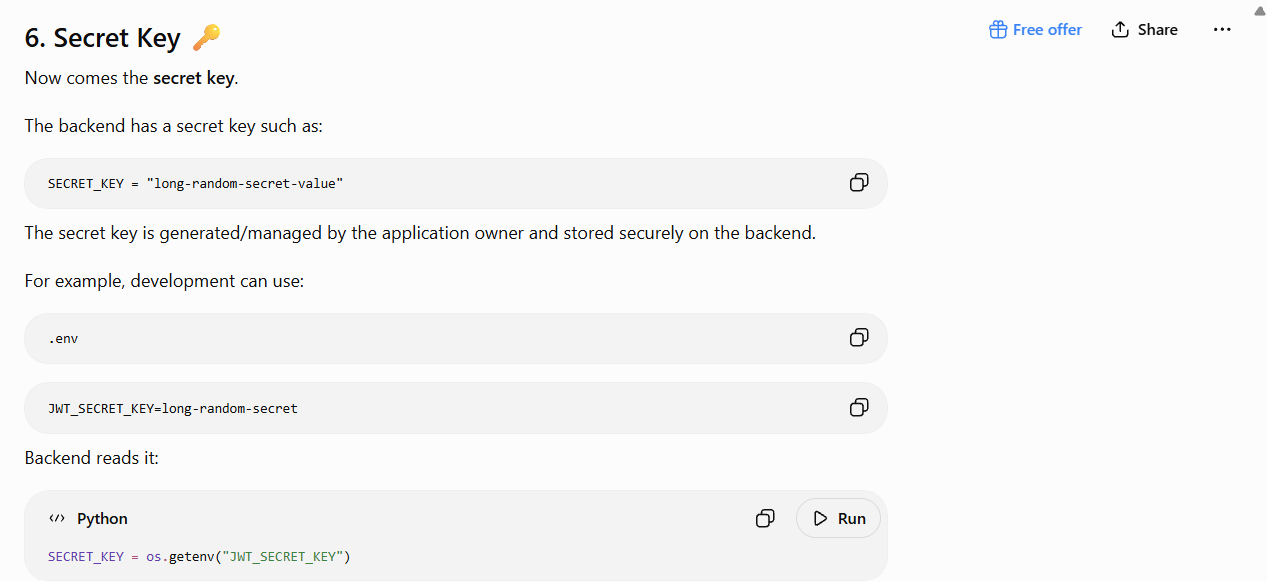

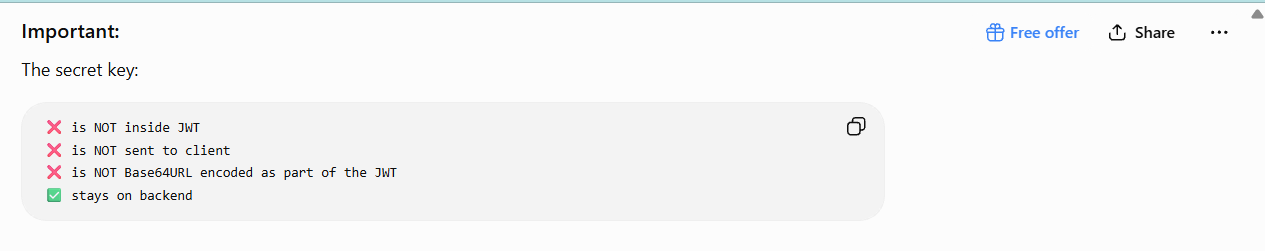

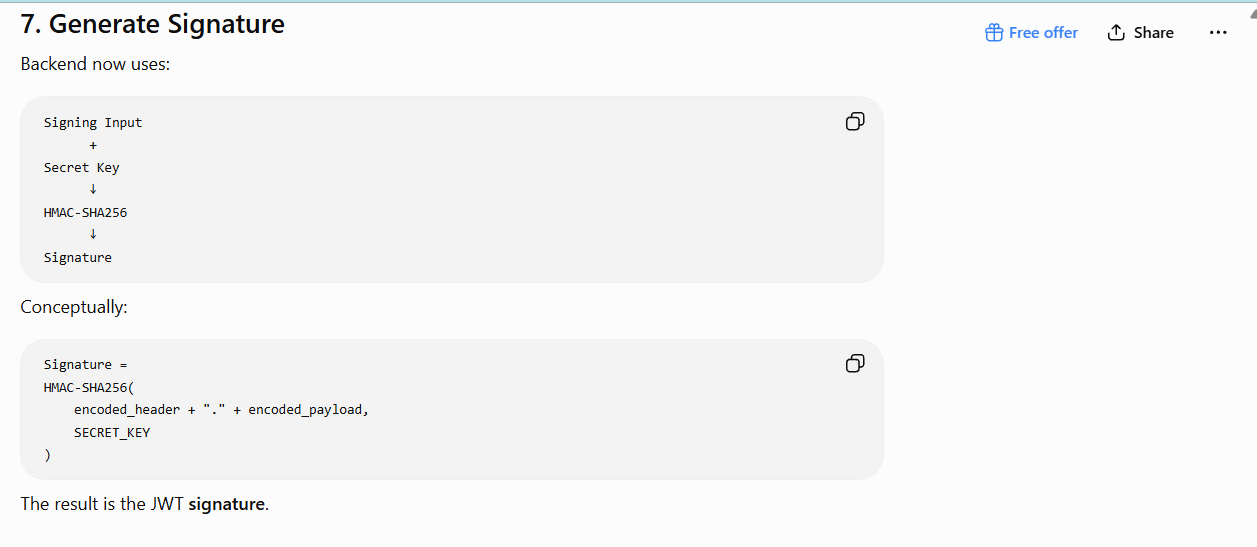

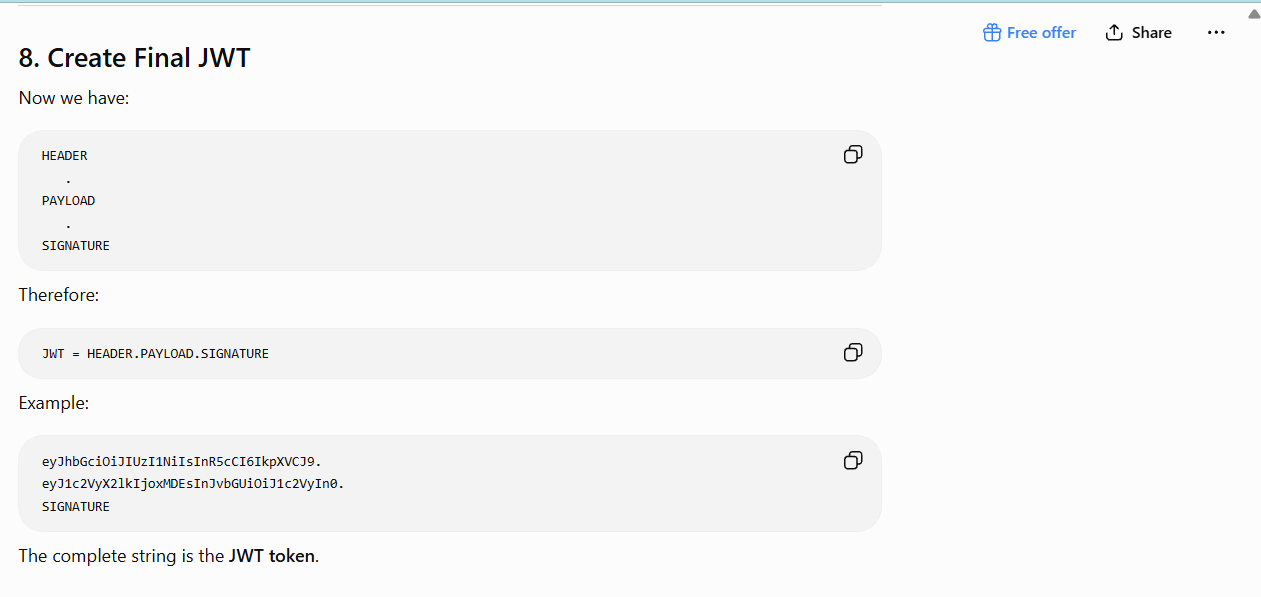

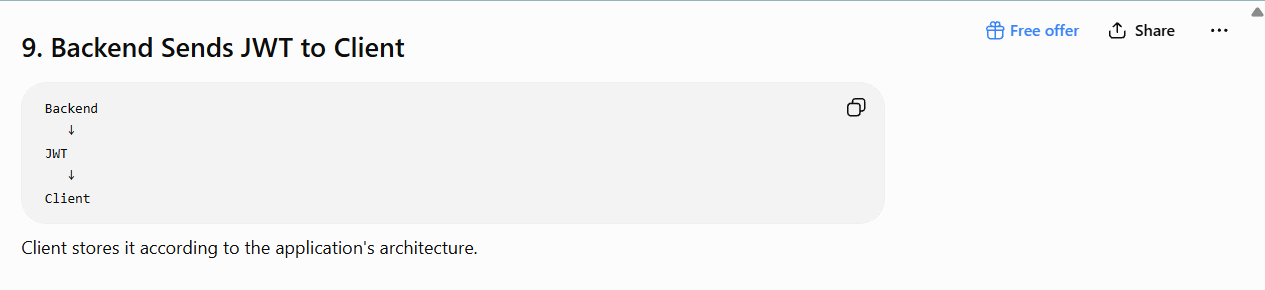

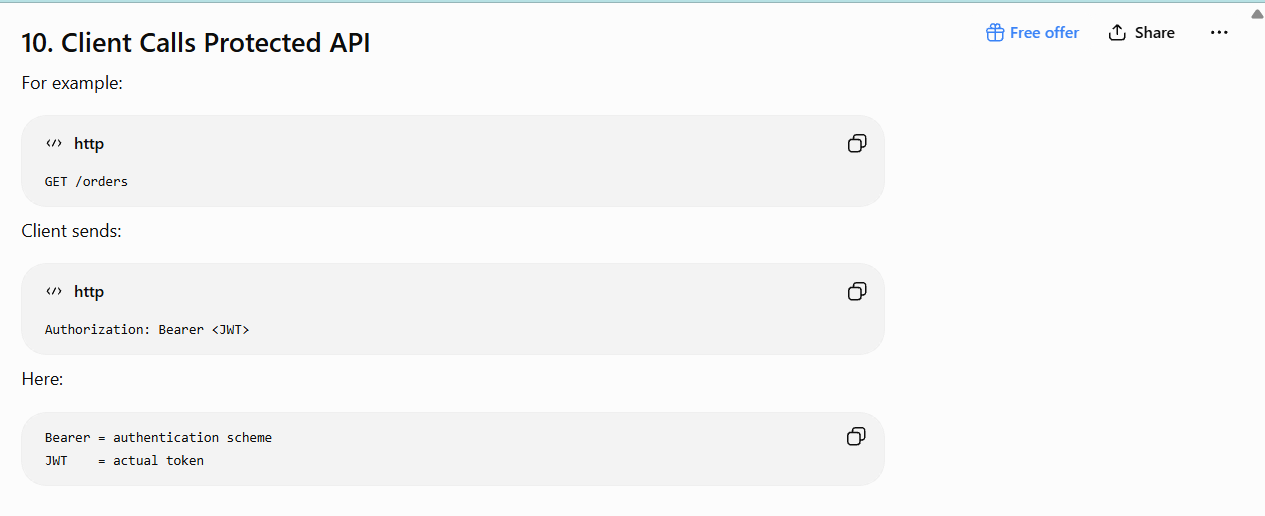

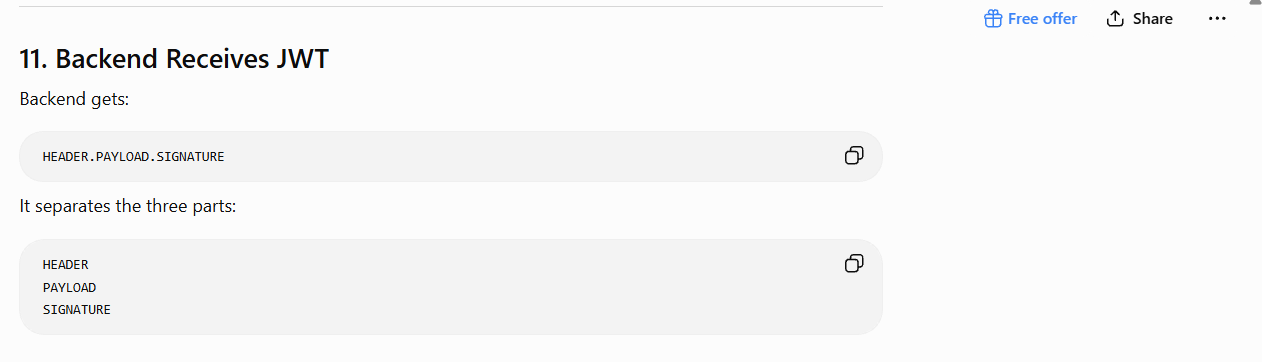

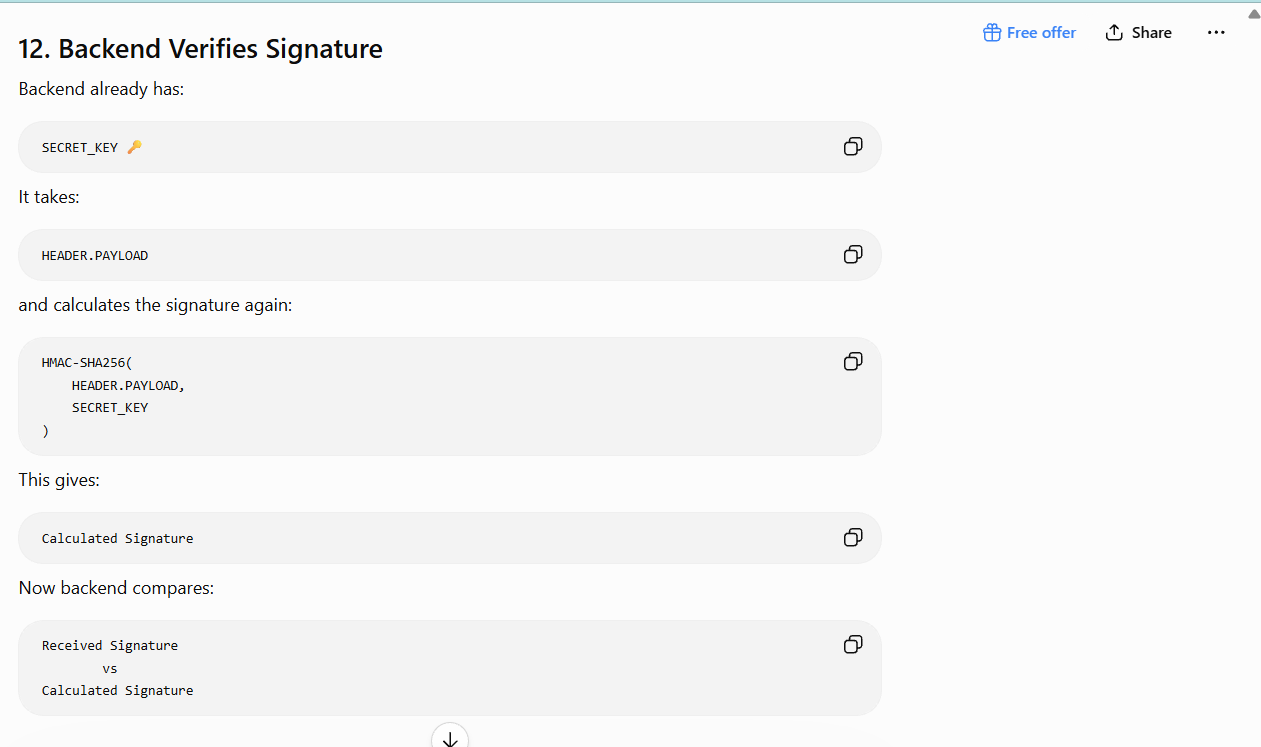

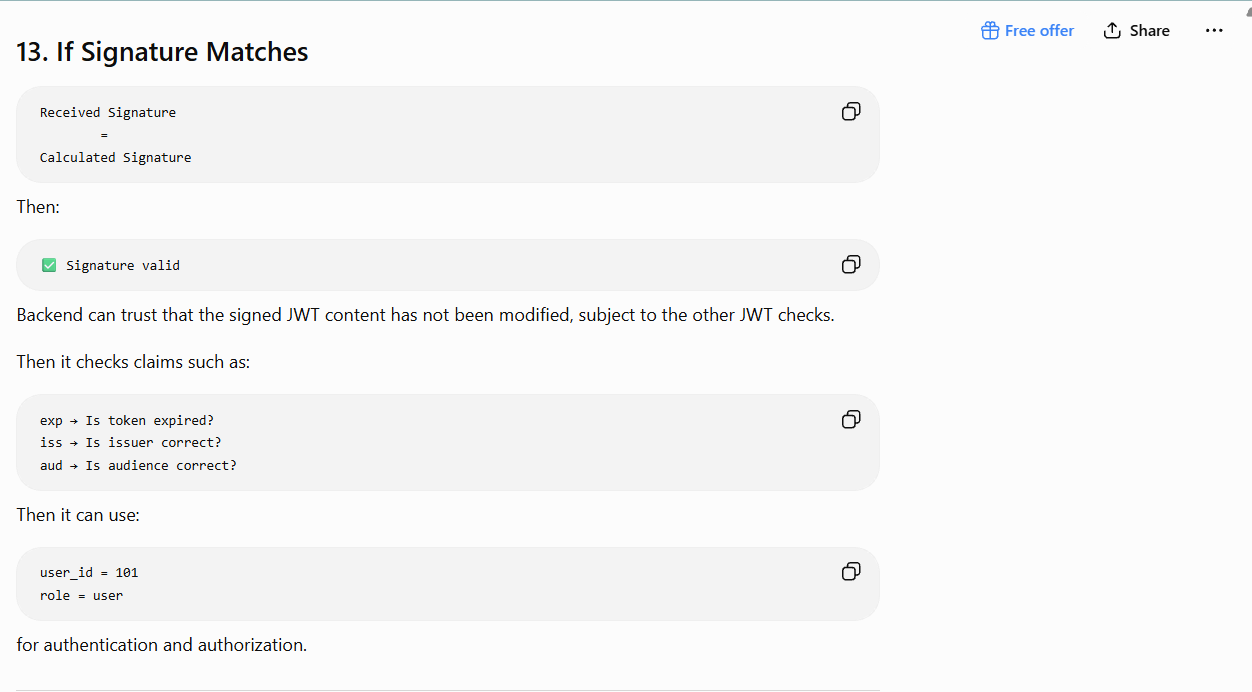

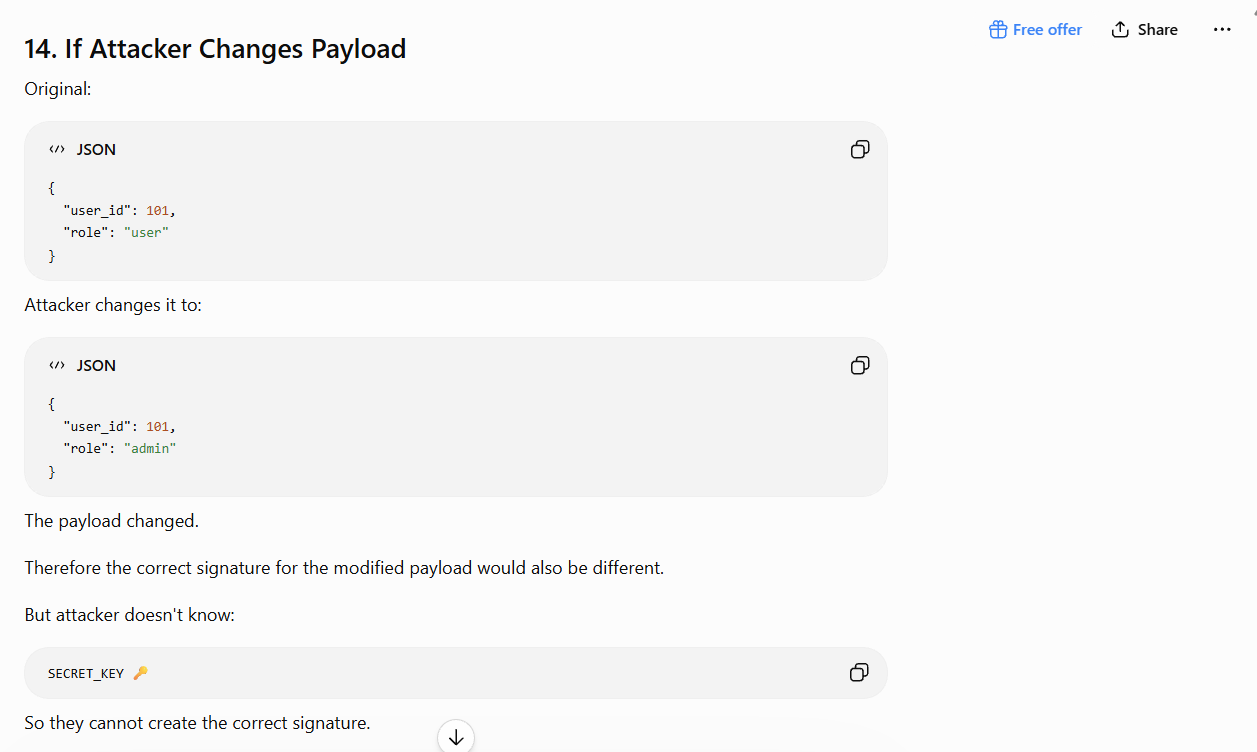

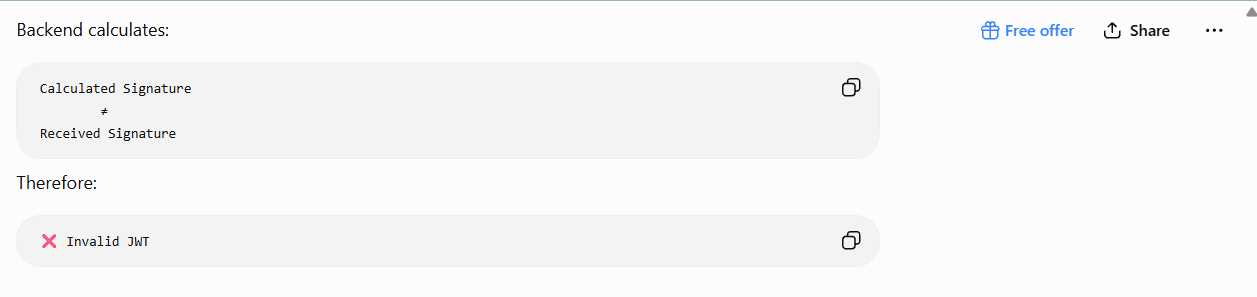

                 LOGIN
                   ↓
          Email + Password
                   ↓
              Backend
                   ↓
          Verify Credentials
                   ↓
          Create Header
                   ↓
          Create Payload
                   ↓
       Base64URL Encode Both
                   ↓
       Header.Payload
                   ↓
              + Secret Key
                   ↓
             HMAC-SHA256
                   ↓
              Signature
                   ↓
      Header.Payload.Signature
                   ↓
                 JWT
                   ↓
                Client
                   ↓
     Authorization: Bearer JWT
                   ↓
                Backend
                   ↓
        Recalculate Signature
          using Secret Key
                   ↓
             Compare
             /       \
          Match     No Match
            ↓          ↓
           ✅         ❌
         Continue    Reject

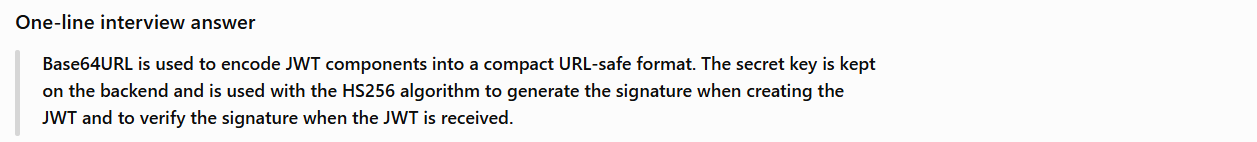